In [1]:
%load_ext autoreload
%autoreload 2

In [9]:
from helper_files.maoa_plate_loader import *
from helper_files.mea_feats_analysis import *
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import warnings


warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)


In [10]:
"""

root_dir = "/Users/blancamartin/Downloads/Sandra_MAOA_MEA/"  # adjust as needed
big_df = summarize_all_spike_files(root_dir, show_progress=True)


"""


'\n\nroot_dir = "/Users/blancamartin/Downloads/Sandra_MAOA_MEA/"  # adjust as needed\nbig_df = summarize_all_spike_files(root_dir, show_progress=True)\n\n\n'

In [13]:
"""#save as pickle 
with open('/Users/blancamartin/Desktop/Muotri_lab/MAOA_pickles/processed_df.pkl', 'wb') as file:
    pickle.dump(big_df, file)"""

"#save as pickle \nwith open('/Users/blancamartin/Desktop/Muotri_lab/MAOA_pickles/processed_df.pkl', 'wb') as file:\n    pickle.dump(big_df, file)"

In [14]:
#open pickle
with open('/Users/blancamartin/Desktop/Muotri_lab/MAOA_pickles/processed_df.pkl', 'rb') as file:
    big_df = pickle.load(file)

In [15]:
#add experiment group
big_df["experiment"] = big_df.apply(
    lambda row: assign_experiment(row["plate_name"], row["recording_date"]),
    axis=1
)

### Exp 3 analysis 

In [17]:
df3 = big_df[big_df["experiment"] == "Exp3"].copy()

df3["firing_mean_hz"] = df3["firing_rate_stats_hz"].str[0]
df3["firing_std_hz"]  = df3["firing_rate_stats_hz"].str[1]
df3["plate_well"] = df3["plate_name"] + "_" + df3["well"]

#remove day sept 26th (bad recording)

#remove bad experiment 
# Convert recording_date safely
df3["recording_date"] = pd.to_datetime(df3["recording_date"], errors="coerce")

# Remove all recordings from Sept 26, 2025
remove_date = pd.to_datetime("2025-09-26")
df3 = df3[df3["recording_date"] != remove_date]



#### Firing rate


=== Plotting Experiment Exp3 ===


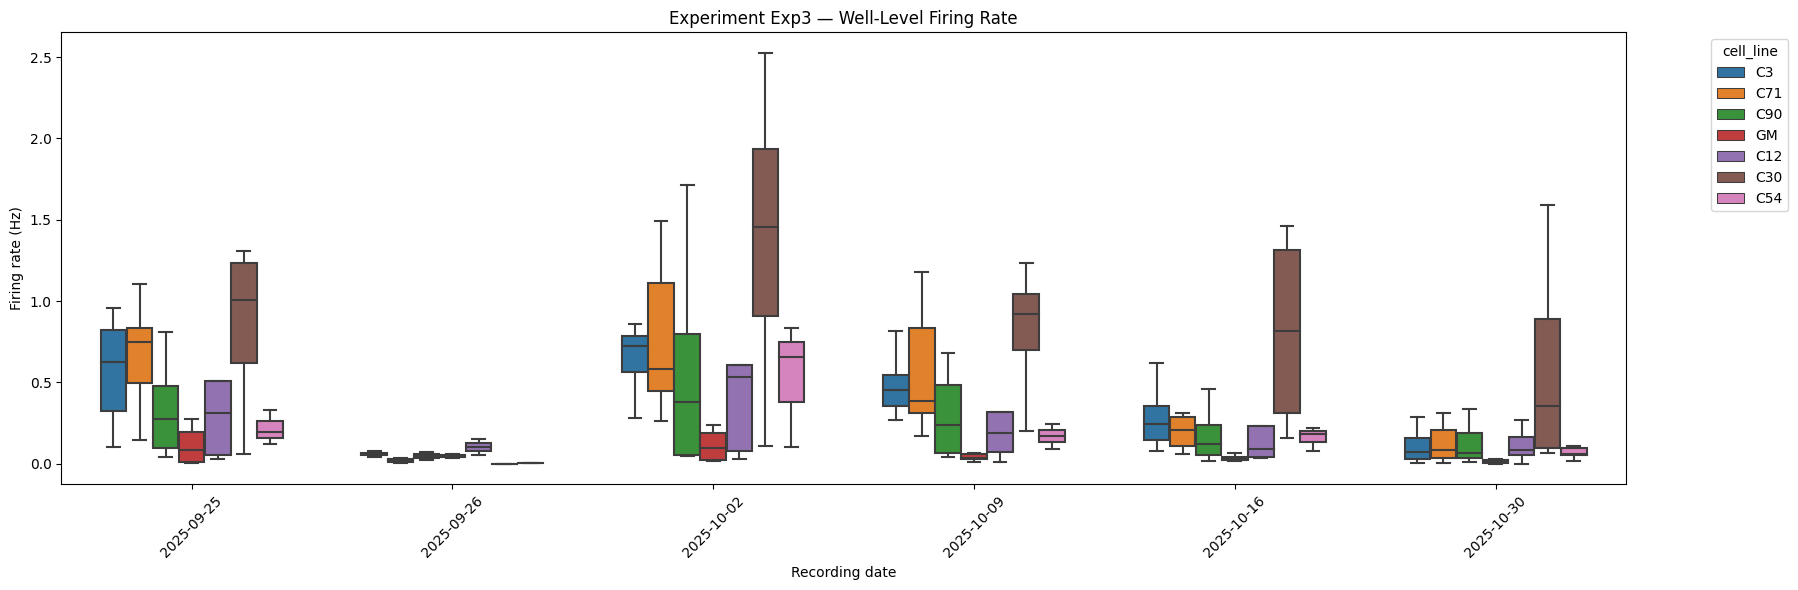

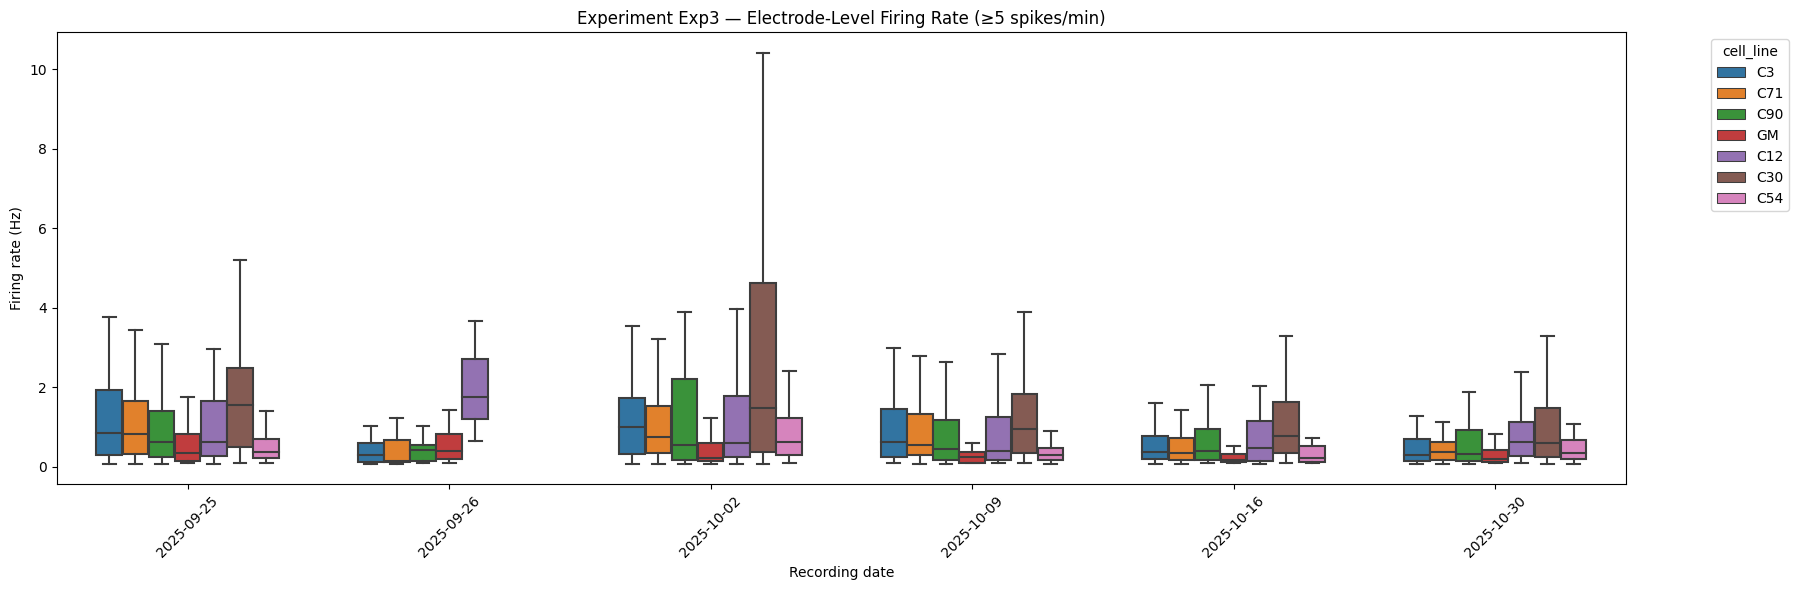

In [7]:
plot_feature_boxplots(df3, "firing")


In [8]:
firing_stats = run_feature_stats(big_df, "firing")


Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


In [9]:
firing_stats["Exp3"]["well"]["two_way_anova"]

,SS,DF,F_statistic,p_value,p_formatted
C(cell_line),8.945240,6.0,12.384069,1.020758e-11,0.000000
C(date_label),7.092670,5.0,11.783176,6.567789e-10,0.000000
C(cell_line):C(date_label),2.073537,30.0,0.574134,9.633882e-01,0.963388
Residual,22.391867,186.0,NaN,NaN,


In [10]:
firing_stats["Exp3"]["electrode"]["two_way_anova"]

,SS,DF,F_statistic,p_value,p_formatted
C(cell_line),317.612399,6.0,15.222406,2.521617e-12,0.000000
C(date_label),414.676597,5.0,23.849355,3.014536e-15,0.000000
C(cell_line):C(date_label),97.491143,30.0,0.934504,5.639556e-01,0.563956
Residual,10248.092066,2947.0,NaN,NaN,


In [11]:
firing_stats["Exp3"]["electrode"]["one_way_anova"]

,SS,DF,F_statistic,p_value,p_formatted
C(cell_line),525.105444,6.0,24.61015,1.291225e-28,0.000000
Residual,10597.349754,2980.0,NaN,NaN,


In [12]:
firing_stats["Exp3"]["well"]["one_way_anova"]

,SS,DF,F_statistic,p_value,p_formatted
C(cell_line),9.031696,6.0,10.541438,2.760410e-10,0.000000
Residual,31.558073,221.0,NaN,NaN,


In [13]:
firing_stats["Exp3"]["electrode"]["posthoc"]

,group1,group2,mean1,mean2,difference,t_stat,p_raw,p_raw_fmt,p_bonf,p_bonf_fmt
0,C12,C3,1.356973,1.103899,0.253075,2.159375,3.124982e-02,0.031250,6.562463e-01,0.656246
1,C12,C30,1.356973,2.064496,-0.707522,-4.078898,4.949005e-05,0.000049,1.039291e-03,0.001039
2,C12,C54,1.356973,0.699149,0.657824,5.081735,5.000246e-07,0.000001,1.050052e-05,0.000011
3,C12,C71,1.356973,1.099313,0.257660,2.195264,2.855514e-02,0.028555,5.996580e-01,0.599658
4,C12,C90,1.356973,1.098662,0.258311,1.929269,5.409710e-02,0.054097,1.000000e+00,1.000000
5,C12,GM,1.356973,0.546356,0.810617,6.386533,3.961490e-10,0.000000,8.319129e-09,0.000000
6,C3,C30,1.103899,2.064496,-0.960597,-6.439799,2.301686e-10,0.000000,4.833540e-09,0.000000
7,C3,C54,1.103899,0.699149,0.404749,4.285693,2.174296e-05,0.000022,4.566021e-04,0.000457
8,C3,C71,1.103899,1.099313,0.004585,0.059502,9.525614e-01,0.952561,1.000000e+00,1.000000
9,C3,C90,1.103899,1.098662,0.005236,0.052132,9.584379e-01,0.958438,1.000000e+00,1.000000


In [14]:
firing_stats["Exp3"]["well"]["posthoc"]

,group1,group2,mean1,mean2,difference,t_stat,p_raw,p_raw_fmt,p_bonf,p_bonf_fmt
0,C12,C3,0.322104,0.369581,-0.047478,-0.499638,6.194000e-01,0.619400,1.000000,1.000000
1,C12,C30,0.322104,0.794180,-0.472076,-3.042761,4.090054e-03,0.004090,0.085891,0.085891
2,C12,C54,0.322104,0.200961,0.121142,1.281561,2.062681e-01,0.206268,1.000000,1.000000
3,C12,C71,0.322104,0.403572,-0.081468,-0.792122,4.313273e-01,0.431327,1.000000,1.000000
4,C12,C90,0.322104,0.251950,0.070154,0.717072,4.762837e-01,0.476284,1.000000,1.000000
5,C12,GM,0.322104,0.057095,0.265009,3.250339,2.696903e-03,0.002697,0.056635,0.056635
6,C3,C30,0.369581,0.794180,-0.424598,-2.997032,5.332908e-03,0.005333,0.111991,0.111991
7,C3,C54,0.369581,0.200961,0.168620,2.400080,2.023070e-02,0.020231,0.424845,0.424845
8,C3,C71,0.369581,0.403572,-0.033990,-0.419084,6.764361e-01,0.676436,1.000000,1.000000
9,C3,C90,0.369581,0.251950,0.117632,1.575864,1.193633e-01,0.119363,1.000000,1.000000


#### Bursting rate


=== Plotting Experiment Exp3 ===


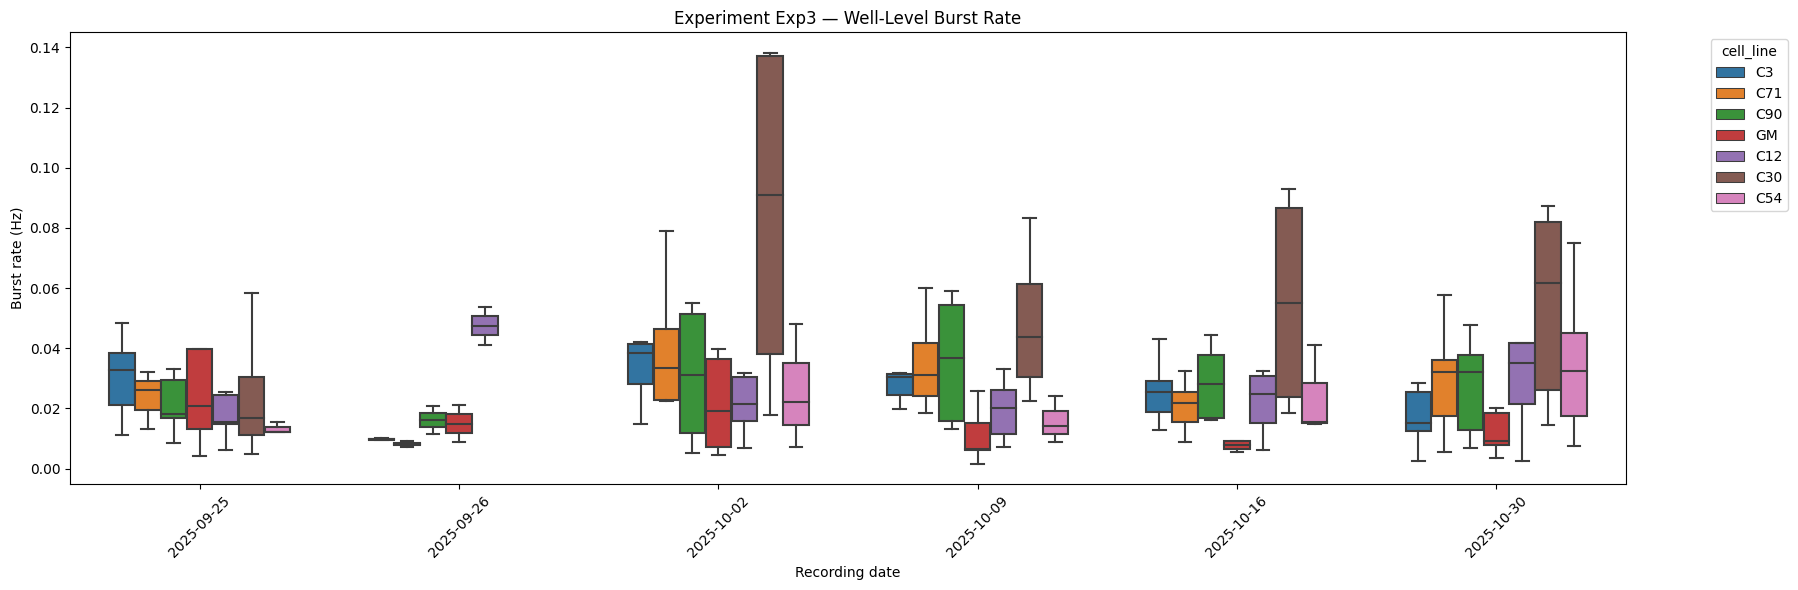

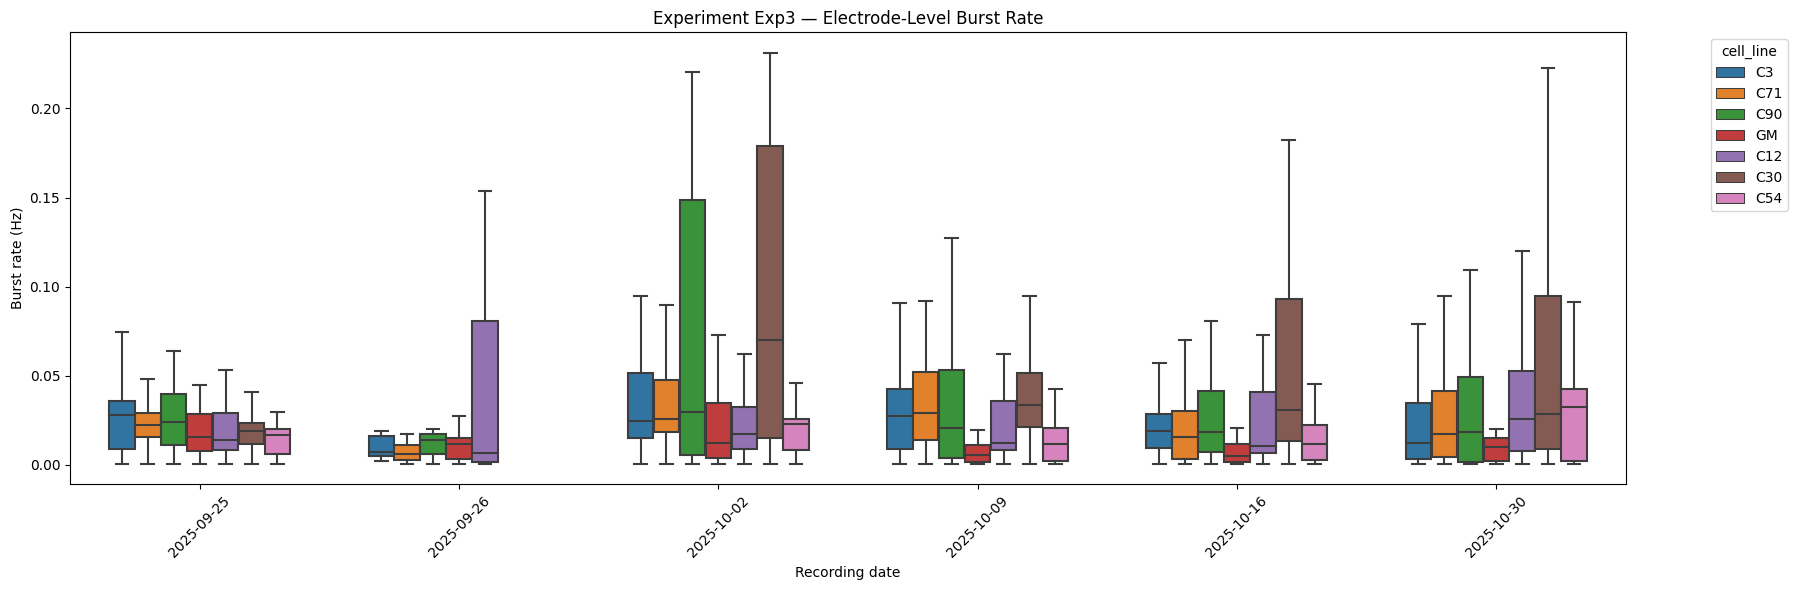

In [15]:
plot_feature_boxplots(df3, "burst")

In [16]:
bursting_stats = run_feature_stats(big_df, "burst")

In [17]:
bursting_stats["Exp3"]["well"]["two_way_anova"]

,SS,DF,F_statistic,p_value,p_formatted
C(cell_line),0.024629,6.0,8.678498,0.000002,0.000002
C(date_label),0.004674,5.0,1.976307,0.119306,0.119306
C(cell_line):C(date_label),0.014659,30.0,1.033073,0.427569,0.427569
Residual,0.082299,174.0,NaN,NaN,


In [18]:
bursting_stats["Exp3"]["electrode"]["two_way_anova"]

,SS,DF,F_statistic,p_value,p_formatted
C(cell_line),0.675217,6.0,62.785572,4.352168e-51,0.000000
C(date_label),0.235556,5.0,26.284055,8.767530e-17,0.000000
C(cell_line):C(date_label),0.254224,30.0,4.727849,4.081662e-15,0.000000
Residual,5.533104,3087.0,NaN,NaN,


In [19]:
bursting_stats["Exp3"]["electrode"]["one_way_anova"]

,SS,DF,F_statistic,p_value,p_formatted
C(cell_line),0.519696,6.0,45.515398,1.136938e-53,0.000000
Residual,5.937376,3120.0,NaN,NaN,


In [20]:
bursting_stats["Exp3"]["well"]["one_way_anova"]

,SS,DF,F_statistic,p_value,p_formatted
C(cell_line),0.019734,6.0,6.748665,0.000002,0.000002
Residual,0.100885,207.0,NaN,NaN,


In [21]:
bursting_stats["Exp3"]["electrode"]["posthoc"]

,group1,group2,mean1,mean2,difference,t_stat,p_raw,p_raw_fmt,p_bonf,p_bonf_fmt
0,C12,C3,0.024687,0.031018,-0.006331,-2.951031,3.237066e-03,0.003237,6.797838e-02,0.067978
1,C12,C30,0.024687,0.059887,-0.035200,-10.470533,8.230410e-24,0.000000,1.728386e-22,0.000000
2,C12,C54,0.024687,0.018392,0.006295,3.399508,7.137180e-04,0.000714,1.498808e-02,0.014988
3,C12,C71,0.024687,0.031392,-0.006705,-3.645602,2.807807e-04,0.000281,5.896395e-03,0.005896
4,C12,C90,0.024687,0.041243,-0.016556,-5.341895,1.351485e-07,0.000000,2.838118e-06,0.000003
5,C12,GM,0.024687,0.015618,0.009068,4.308546,2.075405e-05,0.000021,4.358351e-04,0.000436
6,C3,C30,0.031018,0.059887,-0.028868,-8.219637,8.816758e-16,0.000000,1.851519e-14,0.000000
7,C3,C54,0.031018,0.018392,0.012626,5.976859,3.202057e-09,0.000000,6.724320e-08,0.000000
8,C3,C71,0.031018,0.031392,-0.000374,-0.177913,8.588200e-01,0.858820,1.000000e+00,1.000000
9,C3,C90,0.031018,0.041243,-0.010225,-3.134771,1.796613e-03,0.001797,3.772886e-02,0.037729


In [22]:
bursting_stats["Exp3"]["well"]["posthoc"]

,group1,group2,mean1,mean2,difference,t_stat,p_raw,p_raw_fmt,p_bonf,p_bonf_fmt
0,C12,C3,0.026807,0.027669,-0.000862,-0.187965,0.851520,0.851520,1.000000,1.000000
1,C12,C30,0.026807,0.053857,-0.027050,-3.140913,0.003607,0.003607,0.075741,0.075741
2,C12,C54,0.026807,0.024718,0.002089,0.375475,0.709419,0.709419,1.000000,1.000000
3,C12,C71,0.026807,0.029917,-0.003110,-0.652084,0.516679,0.516679,1.000000,1.000000
4,C12,C90,0.026807,0.029571,-0.002764,-0.561910,0.576103,0.576103,1.000000,1.000000
5,C12,GM,0.026807,0.016943,0.009863,2.117530,0.038498,0.038498,0.808463,0.808463
6,C3,C30,0.027669,0.053857,-0.026188,-3.116323,0.004051,0.004051,0.085063,0.085063
7,C3,C54,0.027669,0.024718,0.002951,0.563892,0.576612,0.576612,1.000000,1.000000
8,C3,C71,0.027669,0.029917,-0.002248,-0.513026,0.609516,0.609516,1.000000,1.000000
9,C3,C90,0.027669,0.029571,-0.001902,-0.418532,0.676833,0.676833,1.000000,1.000000


#### Network event rate


=== Plotting Experiment Exp3 ===


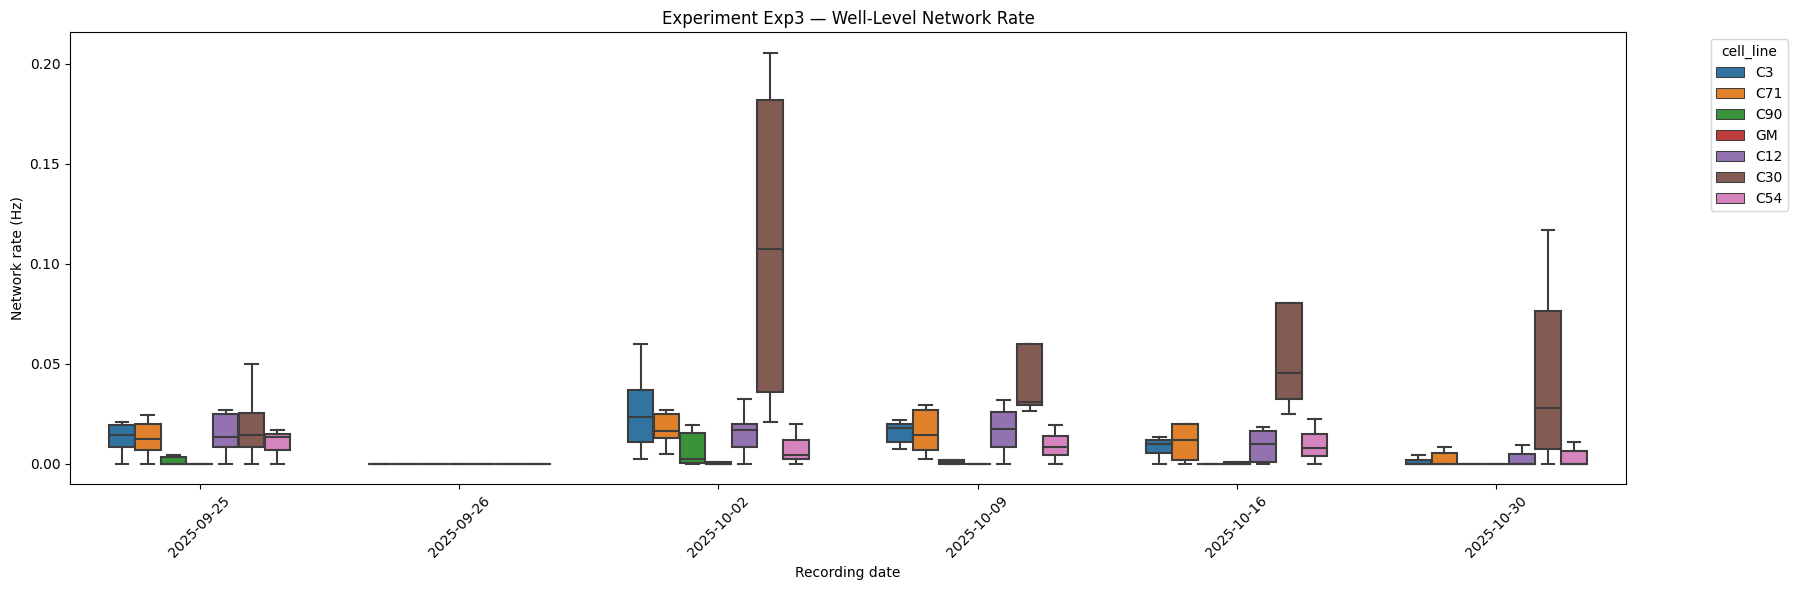

In [23]:
plot_feature_boxplots(df3, "network")

In [24]:
network_stats = run_feature_stats(big_df, "network")

In [25]:
network_stats["Exp3"]["well"]["two_way_anova"]

,SS,DF,F_statistic,p_value,p_formatted
C(cell_line),0.047374,6.0,9.120220,9.513196e-09,0.000000
C(date_label),0.017659,5.0,4.079564,1.544390e-03,0.001544
C(cell_line):C(date_label),0.017452,30.0,0.671952,9.014819e-01,0.901482
Residual,0.161025,186.0,NaN,NaN,


In [26]:
network_stats["Exp3"]["well"]["one_way_anova"]

,SS,DF,F_statistic,p_value,p_formatted
C(cell_line),0.047820,6.0,8.980422,8.780115e-09,0.000000
Residual,0.196136,221.0,NaN,NaN,


In [27]:
network_stats["Exp3"]["well"]["posthoc"]

,group1,group2,mean1,mean2,difference,t_stat,p_raw,p_raw_fmt,p_bonf,p_bonf_fmt
0,C12,C3,0.009941,0.011952,-0.002011,-0.679902,0.498888,0.498888,1.000000,1.000000
1,C12,C30,0.009941,0.054628,-0.044687,-3.738019,0.000955,0.000955,0.020060,0.020060
2,C12,C54,0.009941,0.006867,0.003074,1.160612,0.251718,0.251718,1.000000,1.000000
3,C12,C71,0.009941,0.016160,-0.006219,-1.400165,0.167342,0.167342,1.000000,1.000000
4,C12,C90,0.009941,0.015689,-0.005748,-0.761221,0.450776,0.450776,1.000000,1.000000
5,C12,GM,0.009941,0.002273,0.007668,3.171844,0.002374,0.002374,0.049856,0.049856
6,C3,C30,0.011952,0.054628,-0.042676,-3.552247,0.001500,0.001500,0.031490,0.031490
7,C3,C54,0.011952,0.006867,0.005085,1.750790,0.085683,0.085683,1.000000,1.000000
8,C3,C71,0.011952,0.016160,-0.004208,-0.915135,0.363891,0.363891,1.000000,1.000000
9,C3,C90,0.011952,0.015689,-0.003737,-0.488891,0.627348,0.627348,1.000000,1.000000


#### Synchrony


=== Plotting Experiment Exp3 ===


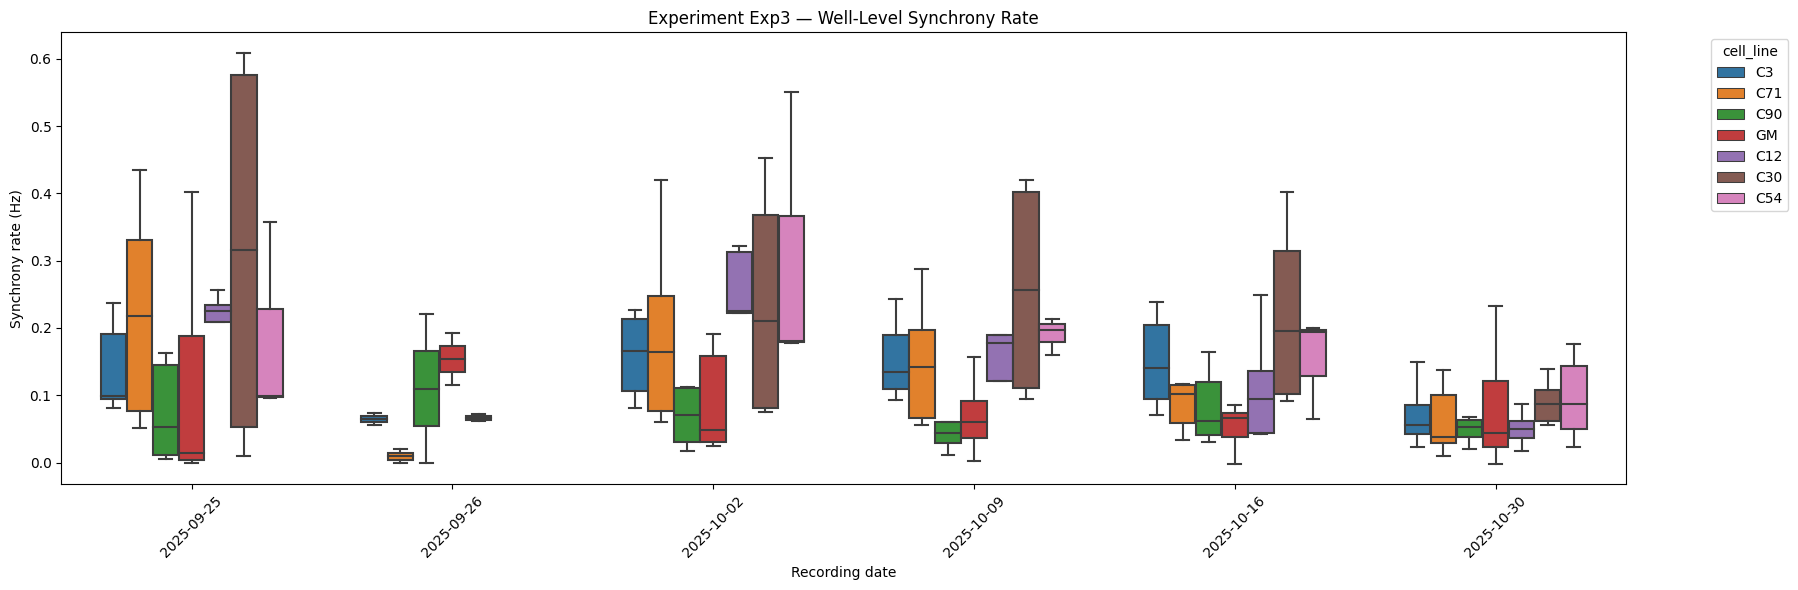

In [28]:
plot_feature_boxplots(df3, "synchrony")

In [29]:
synchrony_stats = run_feature_stats(big_df, "synchrony")

In [30]:
synchrony_stats["Exp3"]["well"]["two_way_anova"]

,SS,DF,F_statistic,p_value,p_formatted
C(cell_line),0.418215,6.0,6.343891,8.425681e-05,0.000084
C(date_label),0.659928,5.0,12.012508,3.269572e-07,0.000000
C(cell_line):C(date_label),0.249857,30.0,0.758016,8.048762e-01,0.804876
Residual,1.999698,182.0,NaN,NaN,


In [31]:
synchrony_stats["Exp3"]["well"]["one_way_anova"]

,SS,DF,F_statistic,p_value,p_formatted
C(cell_line),0.285558,6.0,3.830122,0.001194,0.001194
Residual,2.671582,215.0,NaN,NaN,


In [32]:
synchrony_stats["Exp3"]["well"]["posthoc"]

,group1,group2,mean1,mean2,difference,t_stat,p_raw,p_raw_fmt,p_bonf,p_bonf_fmt
0,C12,C3,0.133816,0.119967,0.013849,0.649221,0.519166,0.519166,1.000000,1.000000
1,C12,C30,0.133816,0.201342,-0.067526,-1.644984,0.109124,0.109124,1.000000,1.000000
2,C12,C54,0.133816,0.170157,-0.036341,-1.057546,0.298577,0.298577,1.000000,1.000000
3,C12,C71,0.133816,0.122957,0.010859,0.413884,0.680307,0.680307,1.000000,1.000000
4,C12,C90,0.133816,0.086629,0.047187,1.921513,0.059127,0.059127,1.000000,1.000000
5,C12,GM,0.133816,0.087884,0.045933,1.863899,0.067005,0.067005,1.000000,1.000000
6,C3,C30,0.119967,0.201342,-0.081375,-2.123301,0.043000,0.043000,0.902997,0.902997
7,C3,C54,0.119967,0.170157,-0.050190,-1.616032,0.120377,0.120377,1.000000,1.000000
8,C3,C71,0.119967,0.122957,-0.002990,-0.137593,0.891038,0.891038,1.000000,1.000000
9,C3,C90,0.119967,0.086629,0.033338,1.695165,0.094864,0.094864,1.000000,1.000000


### Compare three conditions in experiment 3
#### Mutant (c3, c71, c90), WT (c12, c30, c54) and GM
#### and remove recordings from the 26th of September 

In [34]:
removed = df3[df3["recording_date"] == remove_date]
print("Rows removed:", len(removed))


Rows removed: 12


In [35]:
#assign condition groups 
df3_clean = df3_clean.copy()
df3_clean["group3"] = df3_clean["cell_line"].apply(assign_group3)



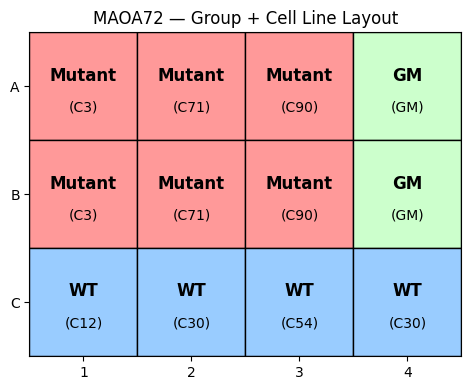

In [36]:
plot_plate_map(df3_clean, "MAOA72", double_label=True)


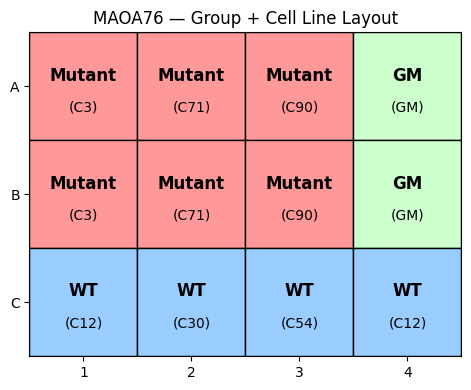

In [43]:
plot_plate_map(df3_clean, "MAOA76", double_label=True)

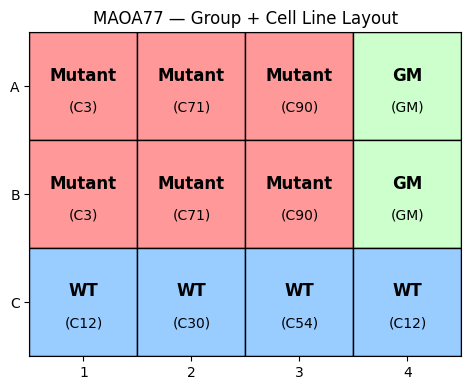

In [44]:
plot_plate_map(df3_clean, "MAOA77", double_label=True)

#### Run stats and plots


=== Plotting Experiment Exp3 ===


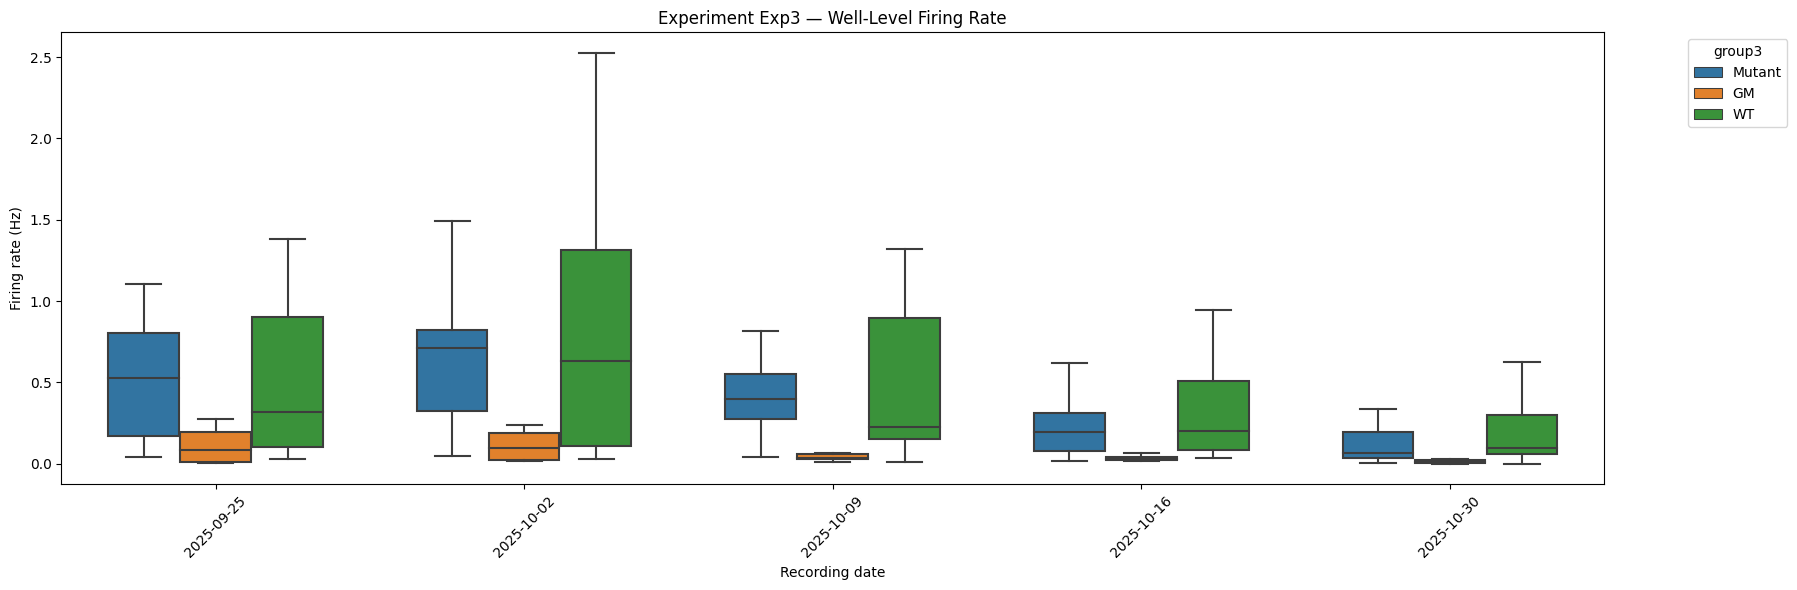

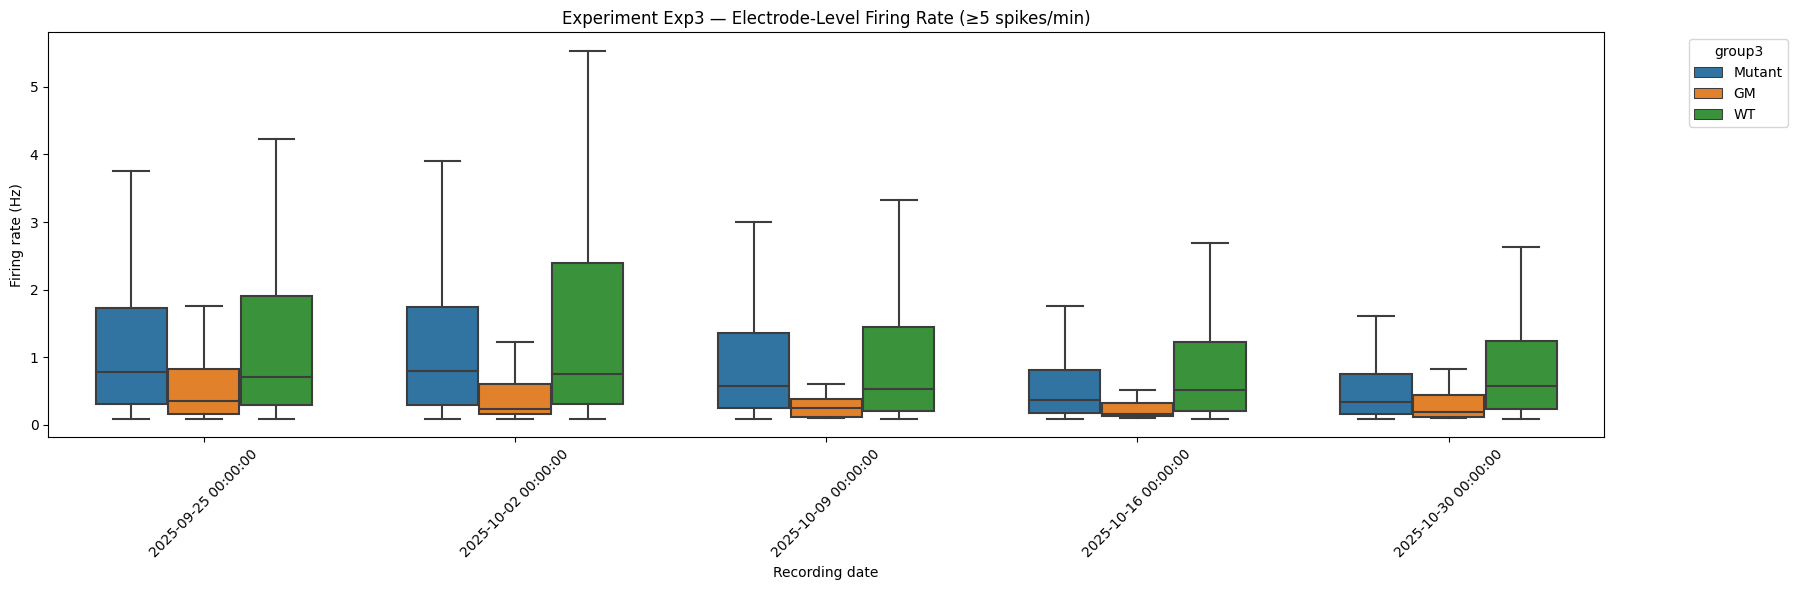

In [37]:
plot_feature_boxplots(df3_clean, "firing", group_col="group3")
group_stats_firing = run_feature_stats(df3_clean, "firing", group_col="group3")



=== Plotting Experiment Exp3 ===


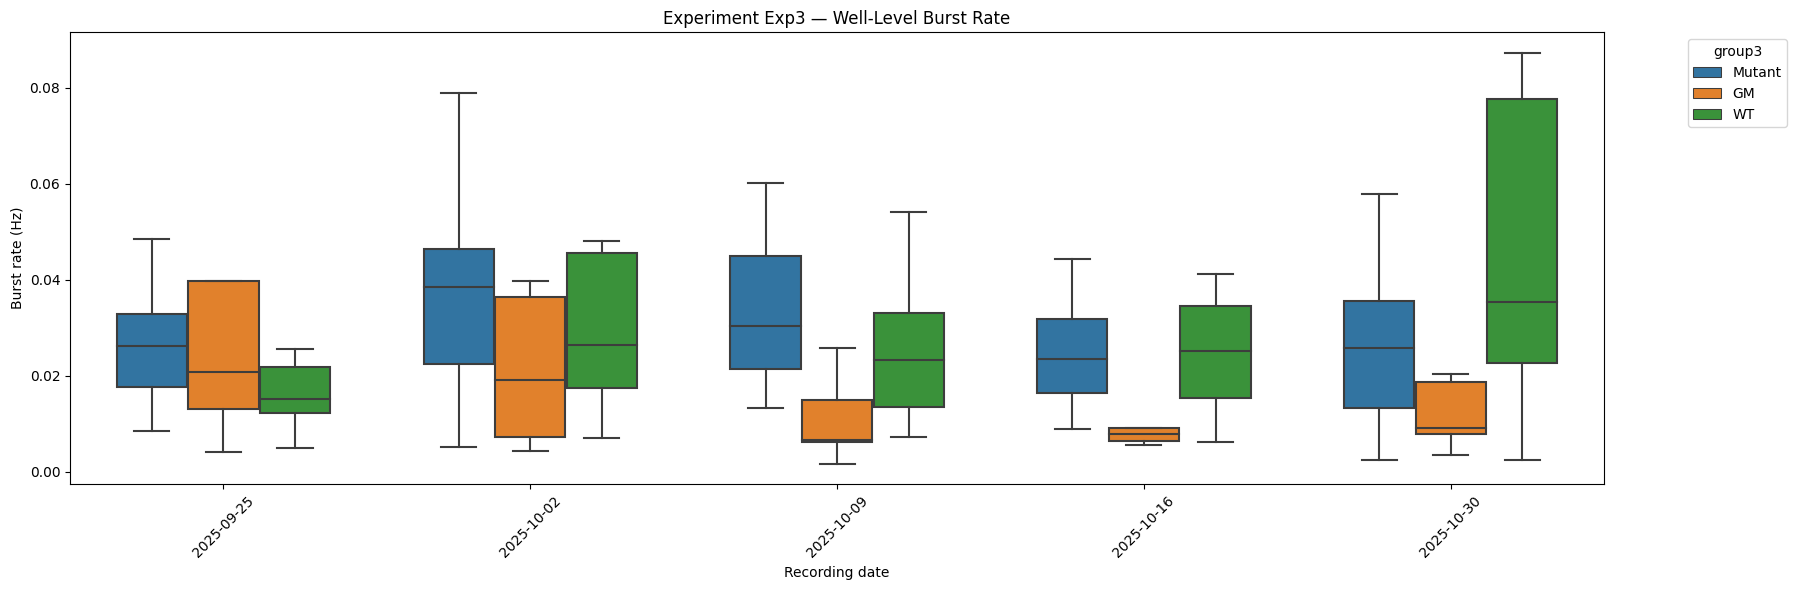

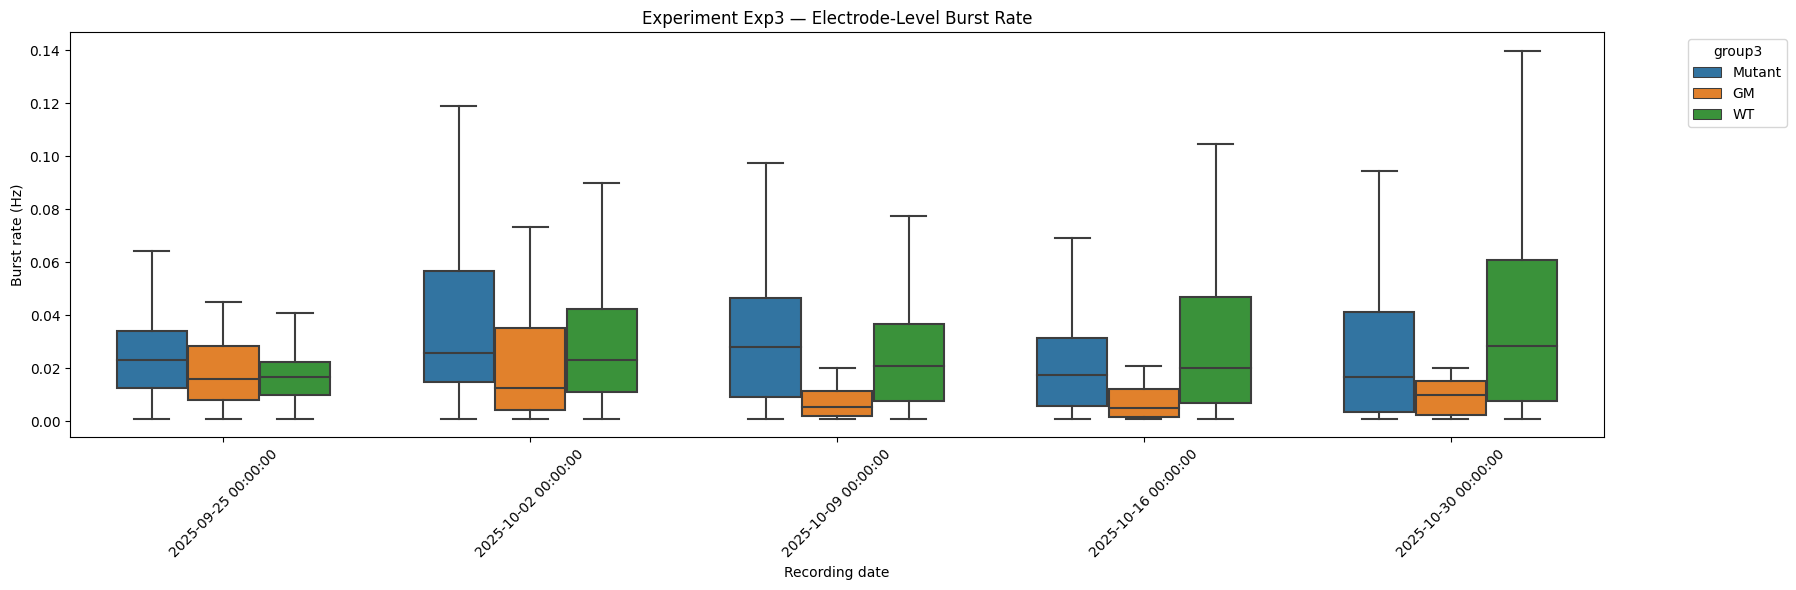

In [38]:
plot_feature_boxplots(df3_clean, "burst", group_col="group3")
group_stats_bursting = run_feature_stats(df3_clean, "burst", group_col="group3")



=== Plotting Experiment Exp3 ===


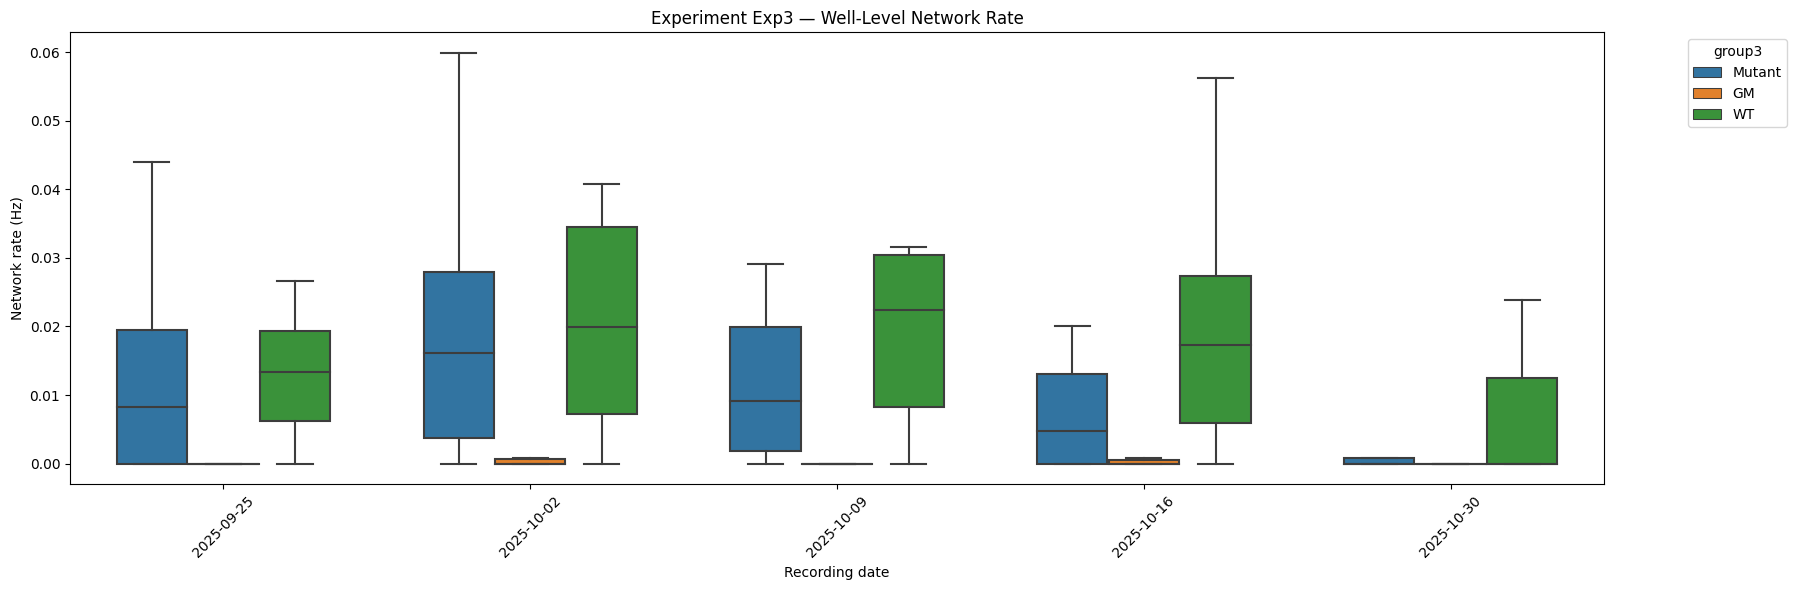

In [39]:
plot_feature_boxplots(df3_clean, "network", group_col="group3")
group_stats_network = run_feature_stats(df3_clean, "network", group_col="group3")



=== Plotting Experiment Exp3 ===


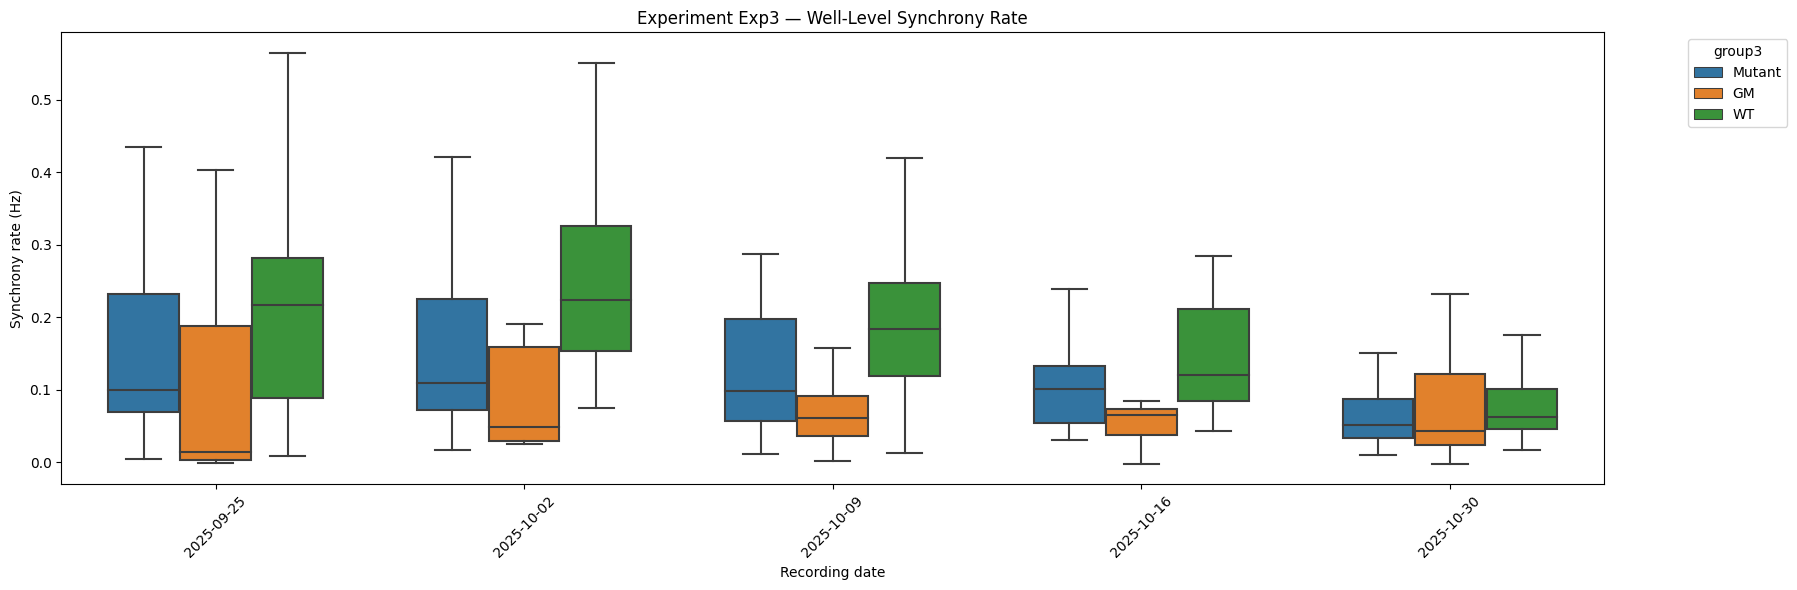

In [40]:
plot_feature_boxplots(df3_clean, "synchrony", group_col="group3")
group_stats_sync = run_feature_stats(df3_clean, "synchrony", group_col="group3")


#### Print stats for groupped results 

Firing 

In [45]:
group_stats_firing["Exp3"]["well"]["two_way_anova"]

,SS,DF,F_statistic,p_value,p_formatted
C(group3),4.102937,2.0,14.576357,1.226269e-06,0.000001
C(date_label),6.166362,4.0,10.953505,4.694595e-08,0.000000
C(group3):C(date_label),1.000126,8.0,0.888278,5.272763e-01,0.527276
Residual,28.288632,201.0,NaN,NaN,


In [46]:
group_stats_firing["Exp3"]["well"]["one_way_anova"]

,SS,DF,F_statistic,p_value,p_formatted
C(group3),4.102937,2.0,12.324393,0.000009,0.000009
Residual,35.455120,213.0,NaN,NaN,


In [47]:
group_stats_firing["Exp3"]["electrode"]["one_way_anova"]

,SS,DF,F_statistic,p_value,p_formatted
C(group3),185.73402,2.0,25.158669,1.464472e-11,0.000000
Residual,10911.34357,2956.0,NaN,NaN,


In [48]:
group_stats_firing["Exp3"]["electrode"]["one_way_anova"]

,SS,DF,F_statistic,p_value,p_formatted
C(group3),185.73402,2.0,25.158669,1.464472e-11,0.000000
Residual,10911.34357,2956.0,NaN,NaN,


In [61]:
group_stats_firing["Exp3"]["electrode"]["posthoc"]

,group1,group2,mean1,mean2,difference,t_stat,p_raw,p_raw_fmt,p_bonf,p_bonf_fmt
0,GM,Mutant,0.545224,1.108218,-0.562994,-6.717740,1.932182e-10,0.000000,5.796546e-10,0.000000
1,GM,WT,0.545224,1.526766,-0.981542,-9.194270,1.250876e-18,0.000000,3.752629e-18,0.000000
2,Mutant,WT,1.108218,1.526766,-0.418548,-5.021918,5.678561e-07,0.000001,1.703568e-06,0.000002


In [62]:
group_stats_firing["Exp3"]["well"]["posthoc"]

,group1,group2,mean1,mean2,difference,t_stat,p_raw,p_raw_fmt,p_bonf,p_bonf_fmt
0,GM,Mutant,0.057527,0.358318,-0.300791,-8.302184,1.169016e-13,0.000000,3.507048e-13,0.000000
1,GM,WT,0.057527,0.469092,-0.411565,-6.194253,2.785979e-08,0.000000,8.357936e-08,0.000000
2,Mutant,WT,0.358318,0.469092,-0.110774,-1.503114,1.356850e-01,0.135685,4.070551e-01,0.407055


Bursting 

In [50]:
group_stats_bursting["Exp3"]["well"]["two_way_anova"]

,SS,DF,F_statistic,p_value,p_formatted
C(group3),0.006530,2.0,6.121495,0.002655,0.002655
C(date_label),0.004441,4.0,2.081674,0.084815,0.084815
C(group3):C(date_label),0.005695,8.0,1.334689,0.228510,0.228510
Residual,0.100804,189.0,NaN,NaN,


In [51]:
group_stats_bursting["Exp3"]["well"]["one_way_anova"]

,SS,DF,F_statistic,p_value,p_formatted
C(group3),0.006329,2.0,5.733446,0.003788,0.003788
Residual,0.110939,201.0,NaN,NaN,


In [52]:
group_stats_bursting["Exp3"]["electrode"]["one_way_anova"]

,SS,DF,F_statistic,p_value,p_formatted
C(group3),0.066695,2.0,16.206923,9.956785e-08,0.000000
Residual,6.351790,3087.0,NaN,NaN,


In [49]:
group_stats_bursting["Exp3"]["electrode"]["one_way_anova"]

,SS,DF,F_statistic,p_value,p_formatted
C(group3),0.066695,2.0,16.206923,9.956785e-08,0.000000
Residual,6.351790,3087.0,NaN,NaN,


In [60]:
group_stats_bursting["Exp3"]["electrode"]["posthoc"]

,group1,group2,mean1,mean2,difference,t_stat,p_raw,p_raw_fmt,p_bonf,p_bonf_fmt
0,GM,Mutant,0.015773,0.033666,-0.017893,-8.986579,3.157533e-17,0.000000,9.472599e-17,0.000000
1,GM,WT,0.015773,0.037333,-0.021560,-9.551638,7.851028e-20,0.000000,2.355309e-19,0.000000
2,Mutant,WT,0.033666,0.037333,-0.003667,-2.034618,4.200715e-02,0.042007,1.260215e-01,0.126021


In [59]:
group_stats_bursting["Exp3"]["well"]["posthoc"]

,group1,group2,mean1,mean2,difference,t_stat,p_raw,p_raw_fmt,p_bonf,p_bonf_fmt
0,GM,Mutant,0.017089,0.030061,-0.012972,-3.429507,0.001270,0.001270,0.003809,0.003809
1,GM,WT,0.017089,0.034838,-0.017749,-3.664755,0.000433,0.000433,0.001299,0.001299
2,Mutant,WT,0.030061,0.034838,-0.004777,-1.180604,0.240322,0.240322,0.720966,0.720966


Network events

In [53]:
group_stats_network["Exp3"]["well"]["one_way_anova"]

,SS,DF,F_statistic,p_value,p_formatted
C(group3),0.012734,2.0,5.944643,0.003074,0.003074
Residual,0.228126,213.0,NaN,NaN,


In [54]:
group_stats_network["Exp3"]["well"]["two_way_anova"]

,SS,DF,F_statistic,p_value,p_formatted
C(group3),0.012734,2.0,6.069209,0.002759,0.002759
C(date_label),0.015009,4.0,3.576795,0.007657,0.007657
C(group3):C(date_label),0.002262,8.0,0.269510,0.975119,0.975119
Residual,0.210855,201.0,NaN,NaN,


In [58]:
group_stats_network["Exp3"]["well"]["posthoc"]

,group1,group2,mean1,mean2,difference,t_stat,p_raw,p_raw_fmt,p_bonf,p_bonf_fmt
0,GM,Mutant,0.002399,0.015411,-0.013012,-3.852626,0.000177,0.000177,0.000530,0.000530
1,GM,WT,0.002399,0.025198,-0.022799,-4.458449,0.000025,0.000025,0.000076,0.000076
2,Mutant,WT,0.015411,0.025198,-0.009787,-1.711364,0.089530,0.089530,0.268590,0.268590


Synchrony

In [55]:
group_stats_sync["Exp3"]["well"]["one_way_anova"]

,SS,DF,F_statistic,p_value,p_formatted
C(group3),0.203403,2.0,7.923422,0.000482,0.000482
Residual,2.682627,209.0,NaN,NaN,


In [56]:
group_stats_sync["Exp3"]["well"]["two_way_anova"]

,SS,DF,F_statistic,p_value,p_formatted
C(group3),0.209993,2.0,9.537292,1.112910e-04,0.000111
C(date_label),0.428537,4.0,9.731479,3.336987e-07,0.000000
C(group3):C(date_label),0.085309,8.0,0.968626,4.617557e-01,0.461756
Residual,2.168781,197.0,NaN,NaN,


In [57]:
group_stats_sync["Exp3"]["well"]["posthoc"]

,group1,group2,mean1,mean2,difference,t_stat,p_raw,p_raw_fmt,p_bonf,p_bonf_fmt
0,GM,Mutant,0.083984,0.112447,-0.028463,-1.456739,0.150966,0.150966,0.452898,0.452898
1,GM,WT,0.083984,0.167751,-0.083767,-3.516918,0.000695,0.000695,0.002086,0.002086
2,Mutant,WT,0.112447,0.167751,-0.055304,-2.910967,0.004332,0.004332,0.012997,0.012997


In [19]:
def run_full_mea_analysis(
    df,
    assign_groups=True,
    use_group3_for_plate_map=False,
    double_label=False,
    threshold_spikes_per_min=5
):
    """
    Master function that:
      1. (Optional) Assigns Mutant/WT/GM groups
      2. Produces plate maps
      3. Runs ALL plots + stats twice:
            • once using cell_line
            • once using group3
      4. Prints stats cleanly
      5. Returns stats dictionary
    """

    df = df.copy()

    # ======================================================
    # 1. ASSIGN GROUPS
    # ======================================================
    if assign_groups:
        df["group3"] = df["cell_line"].apply(assign_group3)
    else:
        if "group3" not in df.columns:
            raise ValueError("assign_groups=False but df has no 'group3' column.")

    # ======================================================
    # 2. GENERATE PLATE MAPS
    # ======================================================
    print("\n### GENERATING PLATE MAPS ###\n")
    for p in sorted(df["plate_name"].unique()):
        print(f" → Plate map for {p}")
        plot_plate_map(
            df,
            plate_name=p,
            use_group3=use_group3_for_plate_map,
            double_label=double_label
        )

    # ======================================================
    # MASTER OUTPUT STRUCTURE
    # ======================================================
    all_stats = {
        "cell_line_analysis": {},
        "group3_analysis": {}
    }

    # ======================================================
    # 3. RUN ANALYSIS #1 — CELL LINE VERSION
    # ======================================================
    print("\n\n########################################")
    print("###  RUNNING ANALYSIS 1: CELL LINES  ###")
    print("########################################\n")

    features = ["firing", "burst", "network", "synchrony"]

    # ---- Plots ----
    for feat in features:
        print(f"\n--- Plotting {feat.upper()} (cell lines) ---")
        plot_feature_boxplots(
            df,
            feature=feat,
            threshold_spikes_per_min=threshold_spikes_per_min
        )

    # ---- Stats ----
    print("\n### STATS FOR CELL LINES ###\n")
    for feat in features:
        print(f"\n============================")
        print(f" STATS — {feat.upper()}  (cell lines)")
        print(f"============================\n")
        stats_res = run_feature_stats(
            df,
            feature=feat,
            threshold_spikes_per_min=threshold_spikes_per_min
        )
        all_stats["cell_line_analysis"][feat] = stats_res

        # Pretty print ANOVA tables
        for exp, expres in stats_res.items():
            print(f"\n--- Experiment {exp} ---")
            if expres["well"]["two_way_anova"] is not None:
                print("\n● TWO-WAY ANOVA (wells)")
                print(expres["well"]["two_way_anova"])
            if expres["well"]["one_way_anova"] is not None:
                print("\n● ONE-WAY ANOVA (wells)")
                print(expres["well"]["one_way_anova"])
            if expres["well"]["posthoc"] is not None:
                print("\n● POST-HOC t-tests (wells)")
                print(expres["well"]["posthoc"])

    # ======================================================
    # 4. RUN ANALYSIS #2 — GROUP3 VERSION
    # ======================================================
    print("\n\n########################################")
    print("###  RUNNING ANALYSIS 2: GROUP3      ###")
    print("########################################\n")

    df_group = df.copy()
    df_group["cell_line"] = df_group["group3"]   # ← key trick

    # ---- Plots ----
    for feat in features:
        print(f"\n--- Plotting {feat.upper()} (group3) ---")
        plot_feature_boxplots(
            df_group,
            feature=feat,
            threshold_spikes_per_min=threshold_spikes_per_min
        )

    # ---- Stats ----
    print("\n### STATS FOR GROUP3 ###\n")
    for feat in features:
        print(f"\n============================")
        print(f" STATS — {feat.upper()}  (group3)")
        print(f"============================\n")
        stats_res_g = run_feature_stats(
            df_group,
            feature=feat,
            threshold_spikes_per_min=threshold_spikes_per_min
        )
        all_stats["group3_analysis"][feat] = stats_res_g

        # Pretty print ANOVA tables
        for exp, expres in stats_res_g.items():
            print(f"\n--- Experiment {exp} ---")
            if expres["well"]["two_way_anova"] is not None:
                print("\n● TWO-WAY ANOVA (wells)")
                print(expres["well"]["two_way_anova"])
            if expres["well"]["one_way_anova"] is not None:
                print("\n● ONE-WAY ANOVA (wells)")
                print(expres["well"]["one_way_anova"])
            if expres["well"]["posthoc"] is not None:
                print("\n● POST-HOC t-tests (wells)")
                print(expres["well"]["posthoc"])

    print("\n\n### FULL ANALYSIS COMPLETE ###\n")

    return all_stats



### GENERATING PLATE MAPS ###

 → Plate map for MAOA72


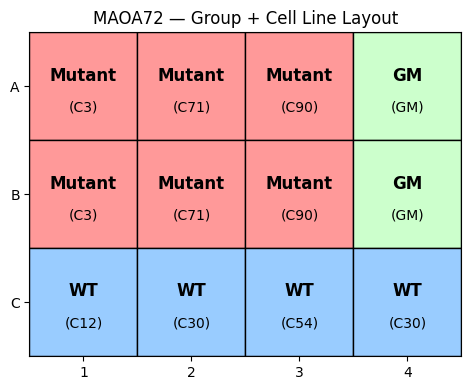

 → Plate map for MAOA76


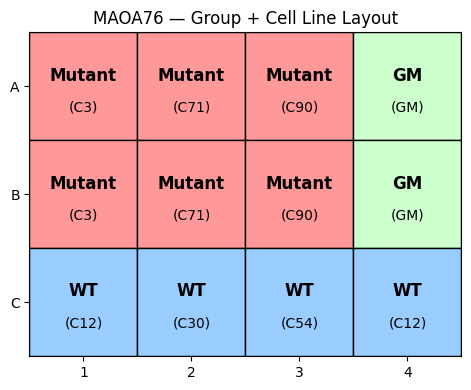

 → Plate map for MAOA77


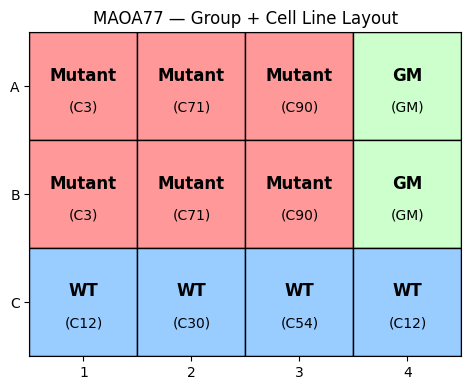



########################################
###  RUNNING ANALYSIS 1: CELL LINES  ###
########################################


--- Plotting FIRING (cell lines) ---

=== Plotting Experiment Exp3 ===


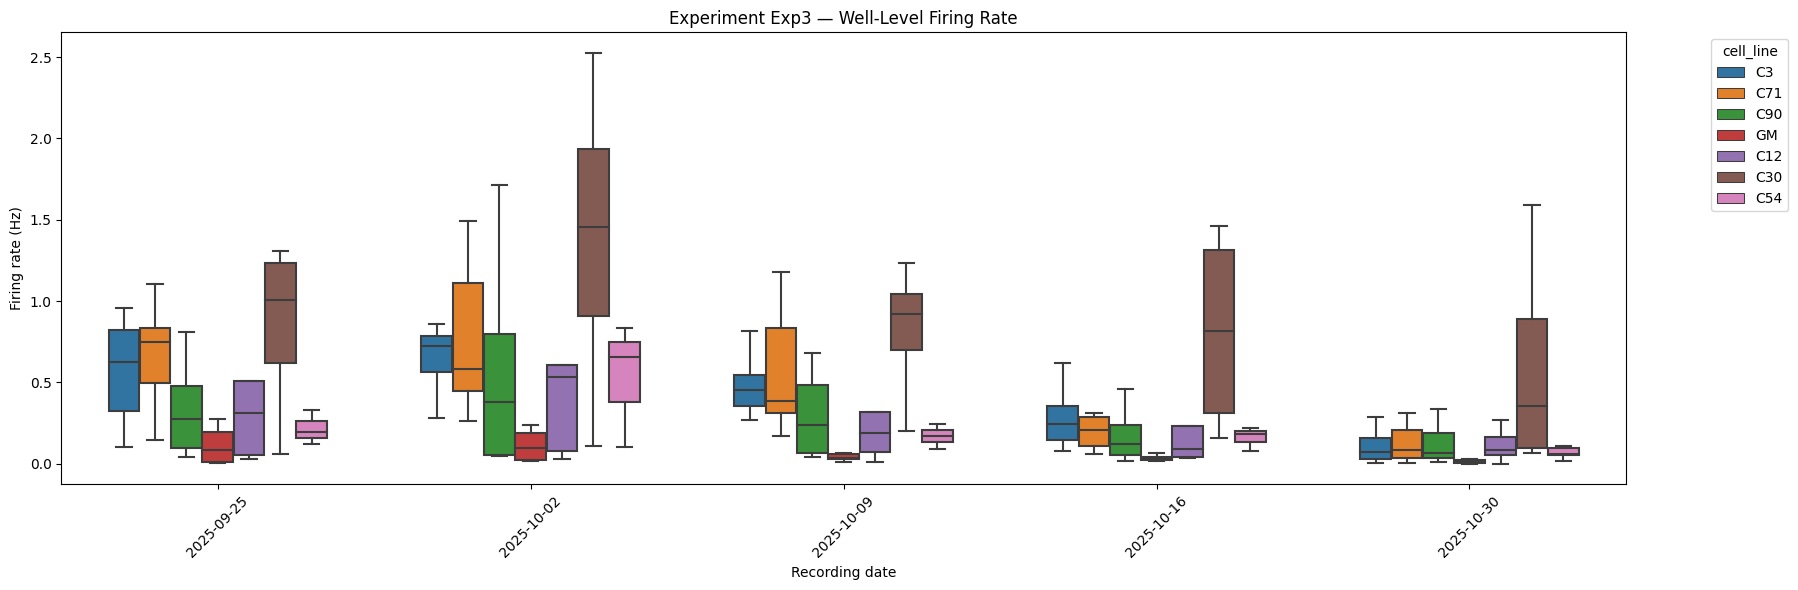

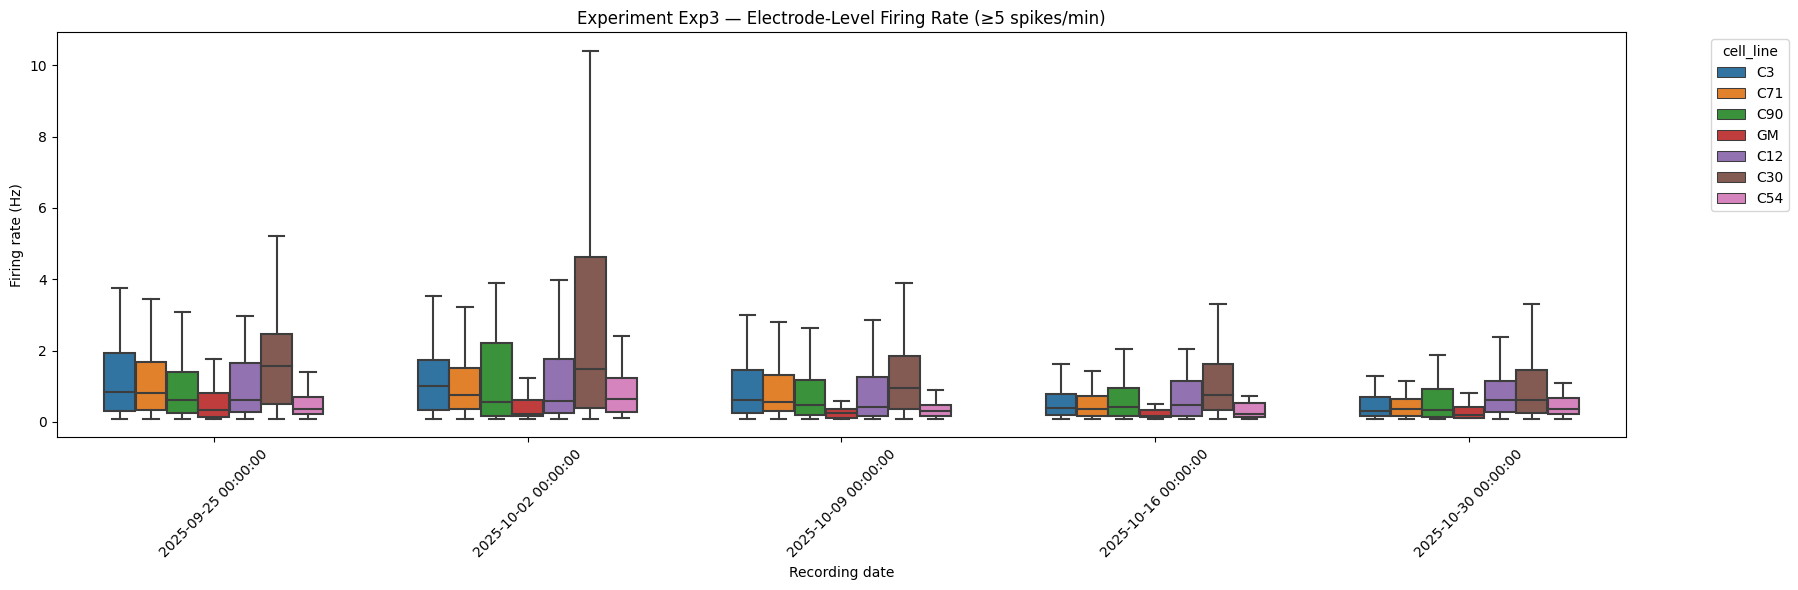


--- Plotting BURST (cell lines) ---

=== Plotting Experiment Exp3 ===


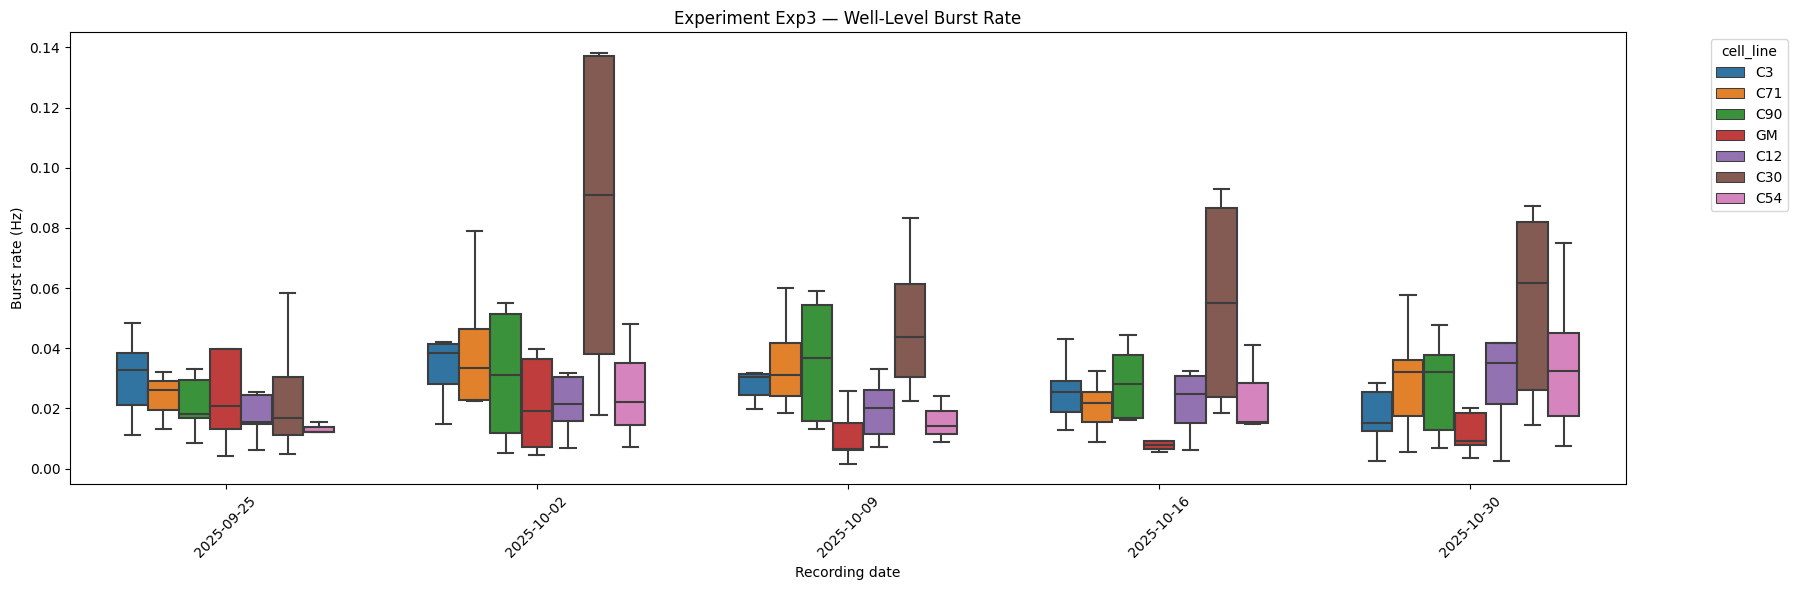

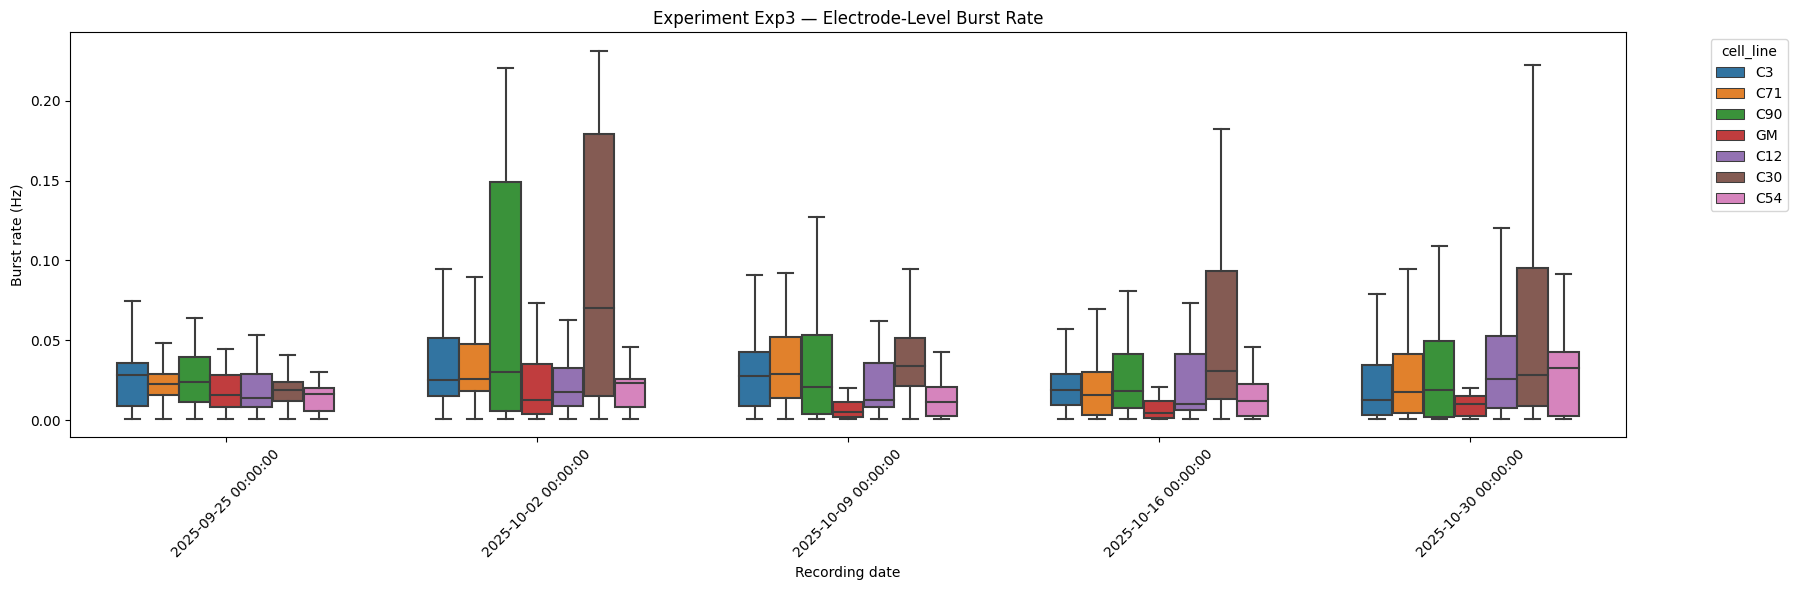


--- Plotting NETWORK (cell lines) ---

=== Plotting Experiment Exp3 ===


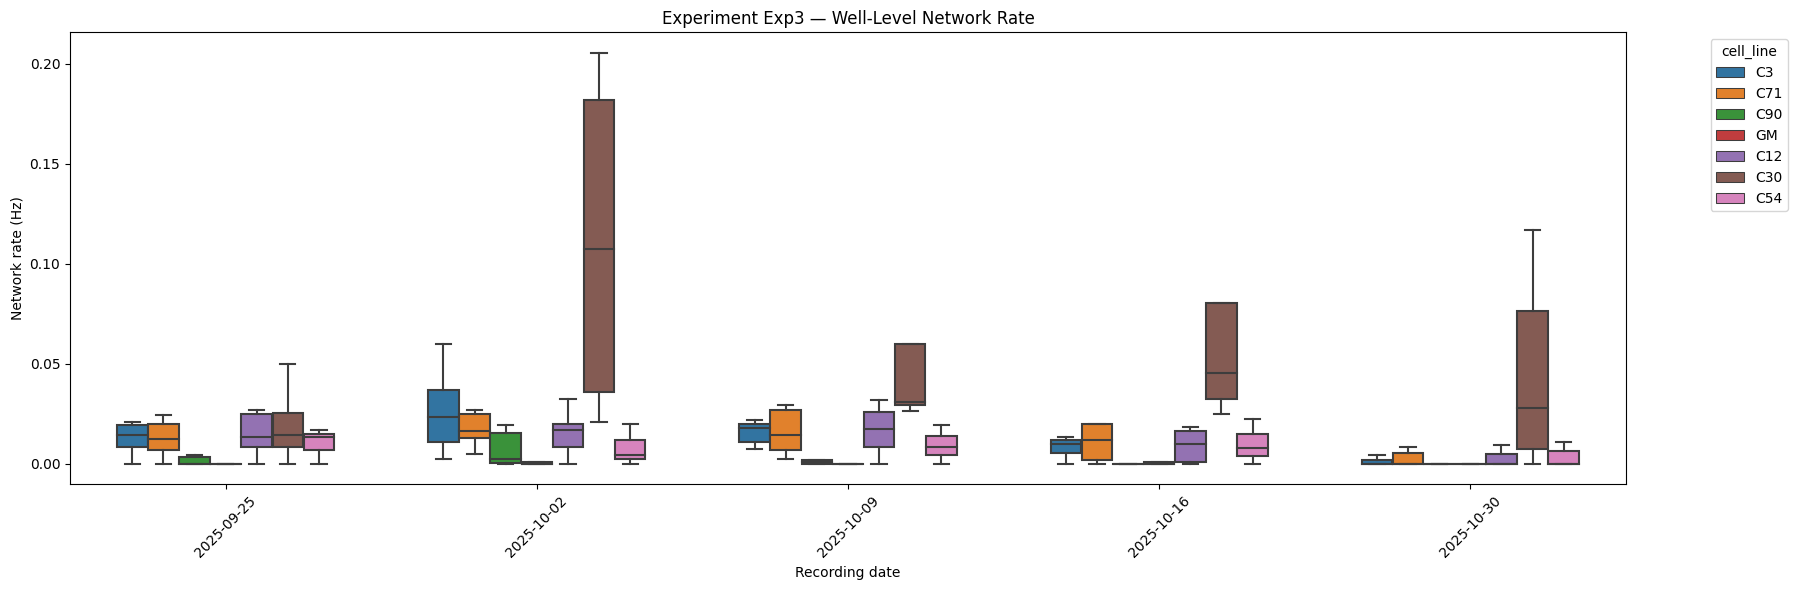


--- Plotting SYNCHRONY (cell lines) ---

=== Plotting Experiment Exp3 ===


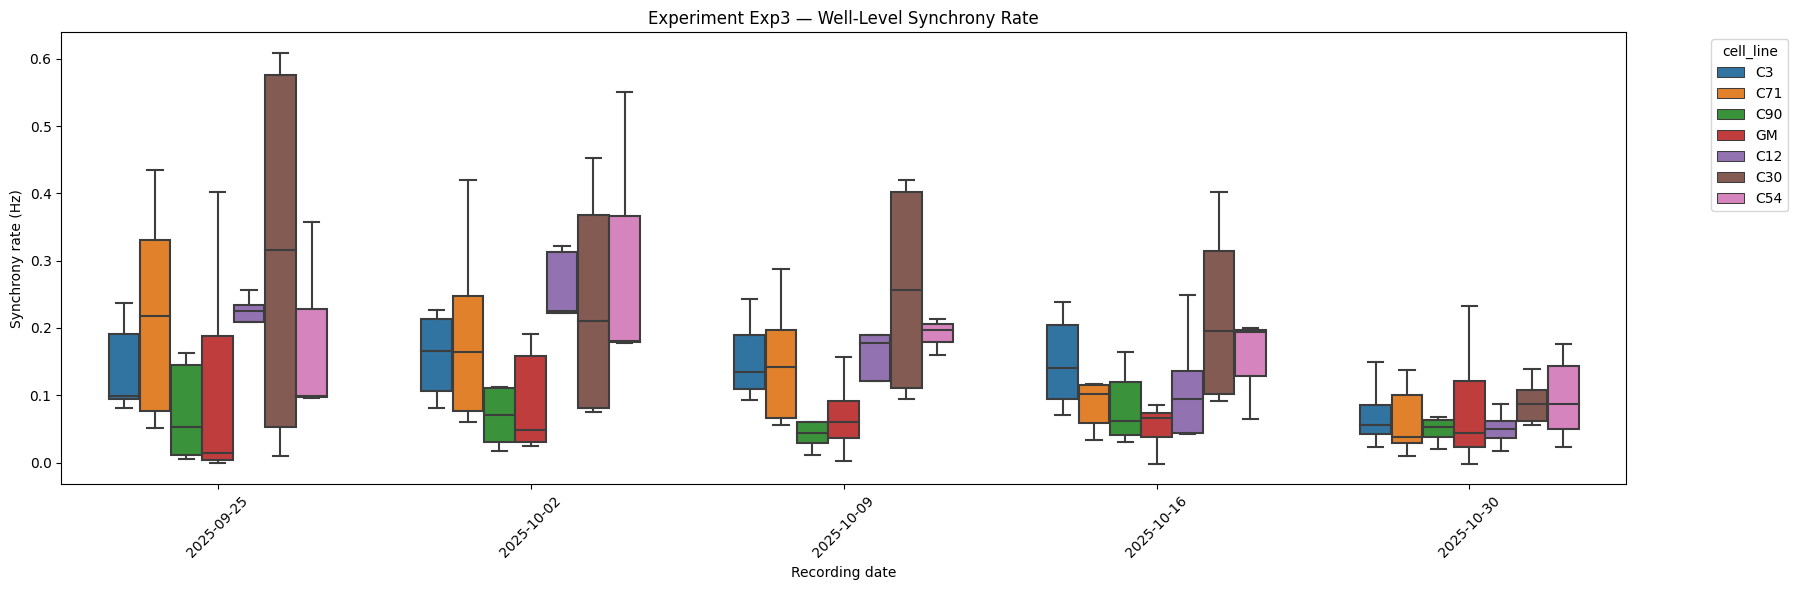


### STATS FOR CELL LINES ###


 STATS — FIRING  (cell lines)


--- Experiment Exp3 ---

● TWO-WAY ANOVA (wells)
                                   SS     DF  F_statistic       p_value  \
C(cell_line)                 9.408586    6.0    12.679590  6.318201e-12   
C(date_label)                6.166362    4.0    12.465253  5.615783e-09   
C(cell_line):C(date_label)   1.598657   24.0     0.538612  9.621447e-01   
Residual                    22.384453  181.0          NaN           NaN   

                           p_formatted  
C(cell_line)                  0.000000  
C(date_label)                 0.000000  
C(cell_line):C(date_label)    0.962145  
Residual                                

● ONE-WAY ANOVA (wells)
                     SS     DF  F_statistic       p_value p_formatted
C(cell_line)   9.408586    6.0    10.870254  1.592894e-10    0.000000
Residual      30.149472  209.0          NaN           NaN            

● POST-HOC t-tests (wells)
   group1 group2     mean1     mean2  diffe

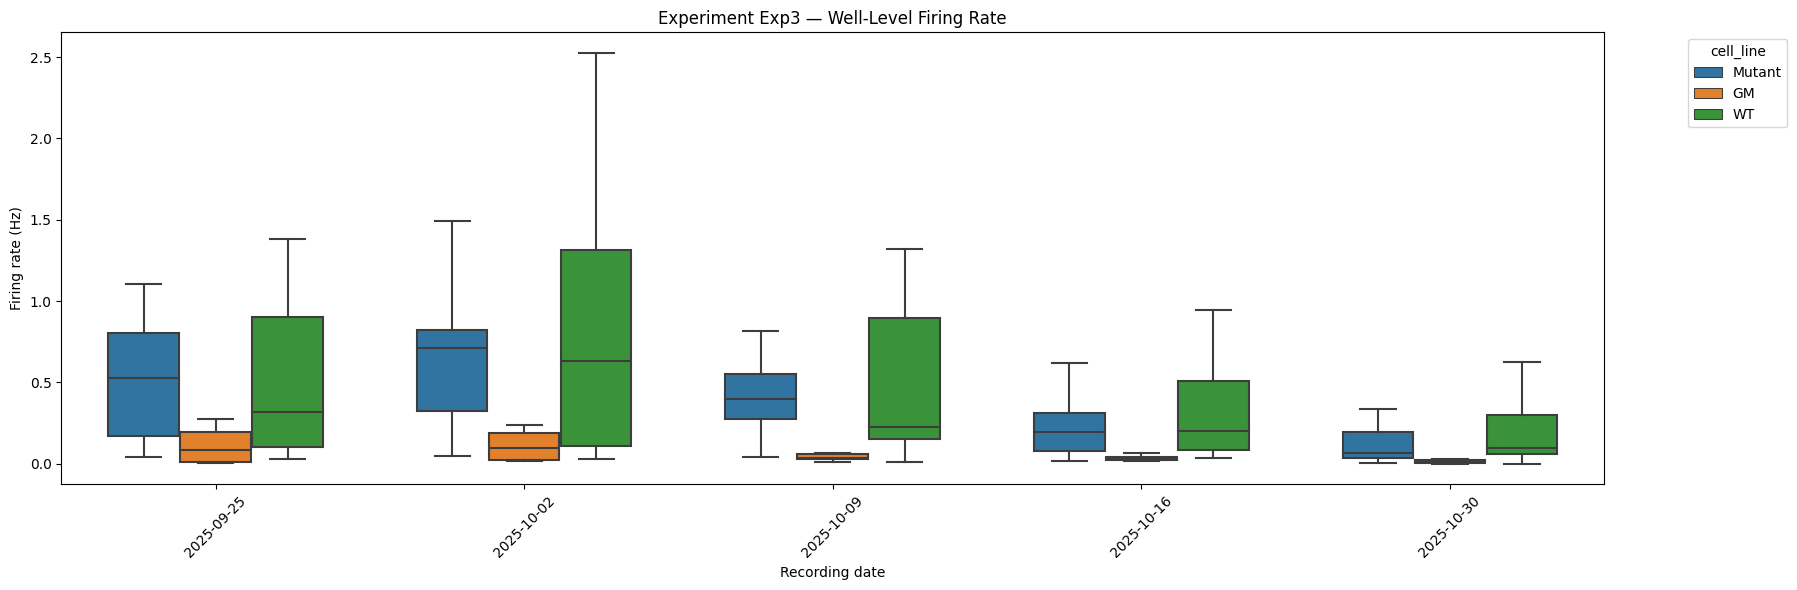

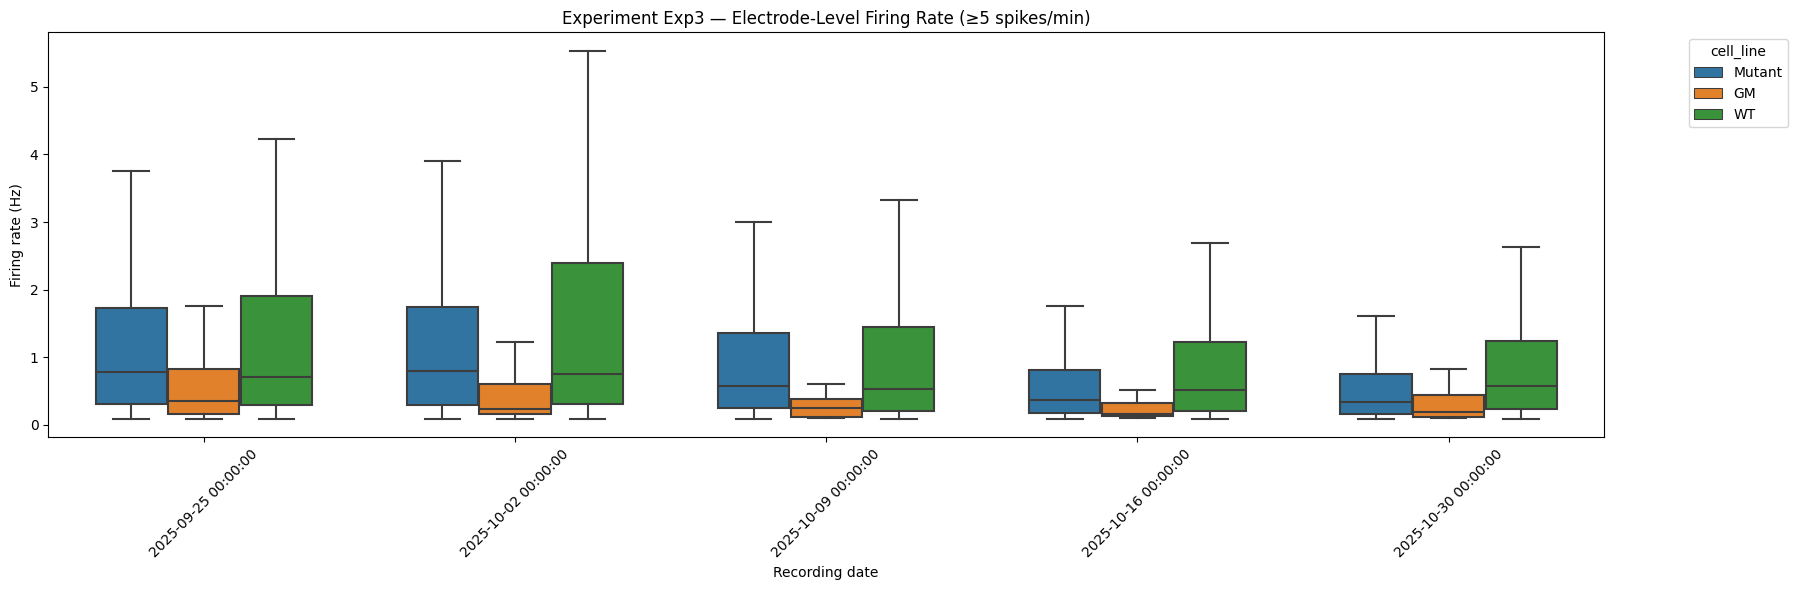


--- Plotting BURST (group3) ---

=== Plotting Experiment Exp3 ===


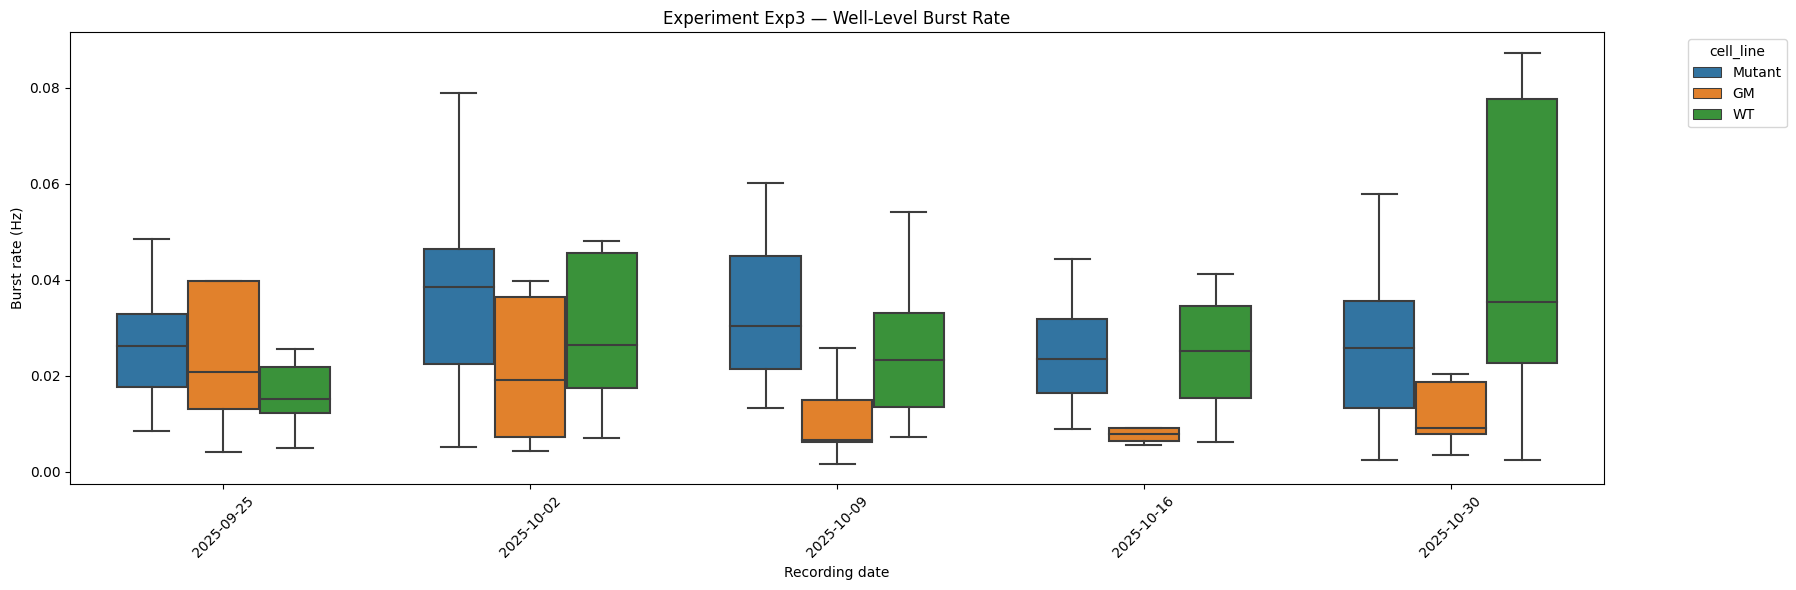

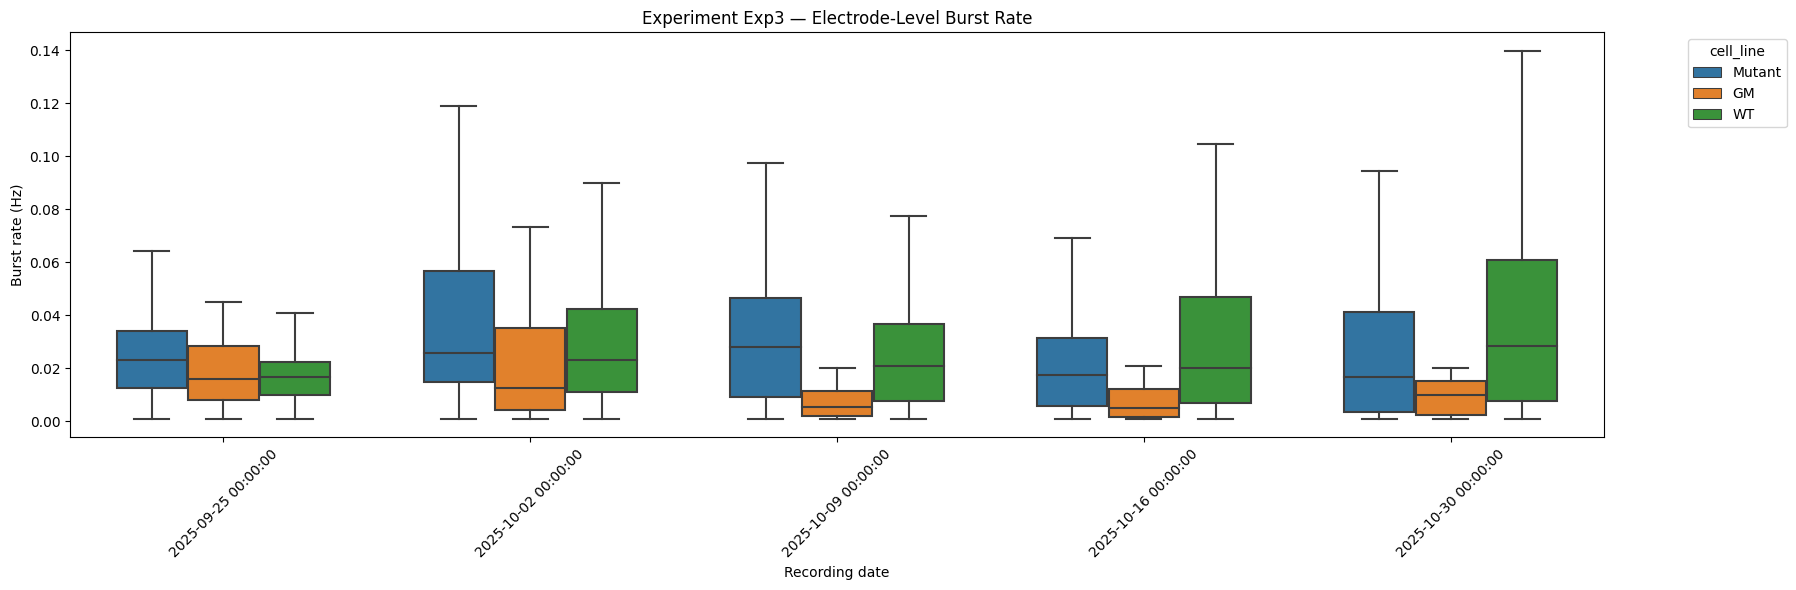

In [ ]:


stats = run_full_mea_analysis(
    df3,
    assign_groups=True,
    use_group3_for_plate_map=True,
    double_label=True
)
